In [1]:
import matplotlib_inline
import matplotlib.pyplot as plt
import numpy as np
import pickle
import matplotlib.image as mpimg
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit
from matplotlib.ticker import FuncFormatter

from joblib import Parallel, delayed

from astropy.coordinates import SkyCoord
import astropy.units as u

In [2]:
niter = 5000
c = 3.0e5  
incl = 61
eincl =2 
pc = 3.086E+18 

perc_low = 16
perc_up = 84
#perc_low = 0.1
#perc_up = 99.9

In [109]:
d10 = 0.222
dim_asec = 1 #15e-3
dim_pc = dim_asec*0.048*d10
dim_pc

0.010656

In [3]:
1.3*np.cos(-25*np.pi/180)/15

0.07854667487650965

In [4]:
incl_rand = np.random.uniform(incl-eincl, incl+eincl, niter)

In [5]:
ra92, dec92 = '18:01:13.0175991356', '-25:43:33.8772313842'
era92, edec92 = '00:00:0.030364', '00:00:1.741535'
ra92_2, dec92_2 = '18:01:12.7471836780', '-25:43:47.2812873130'
era92_2, edec92_2 = '00:00:0.017308', '00:00:0.992684'
ra97, dec97 = '18:01:13.0256799549', '-25:43:34.4991241845'
era97, edec97 = '00:00:0.028368', '00:00:1.362325'
ra01_1, dec01_1 = '18:01:13.2217237541', '-25:43:35.6464914147'
era01_1, edec01_1 = '00:00:0.074547', '00:00:2.061196'
ra01_2, dec01_2 = '18:01:12.8950930545', '-25:43:32.9223482638'
era01_2, edec01_2 = '00:00:0.067407', '00:00:2.097973'
ra08, dec08 = '18:01:13.1326166205', '-25:43:33.3998844486'
#era08, edec08 = '00:00:0.014646', '00:00:1.075642'
#era08, edec08 = '00:00:0.08', '00:00:1.3'
ra16, dec16 = '18:01:13.0372682849', '-25:43:30.7444100293'
era16, edec16 = '00:00:0.022740', '00:00:0.937590'
ra24, dec24 = '18:01:13.0573230433', '-25:43:30.4204045278'
era24, edec24 = '00:00:0.041900', '00:00:0.628499'

#####################################################################################################

cra97, cdec97 = '18:01:12.4092339640', '-25:44:35.6819688406'
ecra97, ecdec97 = '00:00:0.021055', '00:00:1.011126'
cra01, cdec01 = '18:01:12.4155558032', '-25:44:35.9858130142'
ecra01, ecdec01 = '00:00:0.023374', '00:00:0.646288'
cra08, cdec08 = '18:01:12.4000017582', '-25:44:35.0000179093'
ecra08, ecdec08 = '00:00:0.018879', '00:00:1.386526'
cra16, cdec16 = '18:01:12.3912830075', '-25:44:36.0691555263 '
ecra16, ecdec16 = '00:00:0.011307', '00:00:0.558335'
cra24, cdec24 = '18:01:12.3843240765', '-25:44:35.6141169452'
ecra24, ecdec24 = '00:00:0.020090', '00:00:0.301351'

In [6]:
def errors_radec(peak, rms, bmaj, bmin, pa):
    snr = peak/rms
    if snr>10:
        snr = 10
    eRAasec = (np.sqrt((bmaj*np.sin(np.pi*pa/180))**2+(bmin*np.cos(np.pi*pa/180))**2))/snr
    eRA = eRAasec/15/np.cos(np.pi*pa/180)
    eDEC = (np.sqrt((bmaj*np.cos(np.pi*pa/180))**2+(bmin*np.sin(np.pi*pa/188))**2))/snr
    return eRA, eDEC

def hourstring(sec_value):
    sign = '-' if sec_value < 0 else '+'
    sec_value = abs(sec_value)
    h = int(sec_value//3600)
    m = int((sec_value-h*3600)//60)
    s = sec_value-h*3600-m*60
    return f"{sign}{h:02d}:{m:02d}:{s:02.2f}"

In [7]:
peak92, rms92, bmaj92, bmin92, pa92 = 1.05526e-4, 2e-5, 9.89612, 4.55978, -8.69641
era92, edec92 = errors_radec(peak92, rms92, bmaj92, bmin92, pa92)
print(era92, edec92)
era92, edec92 = hourstring(era92), hourstring(edec92)
print(era92, edec92)

peak97, rms97, bmaj97, bmin97, pa97 = 1.29108e-4, 1.4e-5, 9.07794, 4.97039, 5.03504
era97, edec97 = errors_radec(peak97, rms97, bmaj97, bmin97, pa97)
print(era97, edec97)
era97, edec97 = hourstring(era97), hourstring(edec97)
print(era97, edec97)

peak08, rms08, bmaj08, bmin08, pa08 = 1.09673e-4, 1.2e-5, 9.16797, 4.14249, 0.319589
era08, edec08 = errors_radec(peak08, rms08, bmaj08, bmin08, pa08)
era08, edec08 = hourstring(era08), hourstring(edec08)
print(era08, edec08)

peak16, rms16, bmaj16, bmin16, pa16 = 7.374e-5, 6.14e-6, 8.95387, 4.06828, 12.5861
era16, edec16 = errors_radec(peak16, rms16, bmaj16, bmin16, pa16)
era16, edec16 = hourstring(era16), hourstring(edec16)
print(era16, edec16)

peak24, rms24, bmaj24, bmin24, pa24 = 2.16753e-4, 9e-6, 6.33185, 6.33185, 0.0
era24, edec24 = errors_radec(peak24, rms24, bmaj24, bmin24, pa24)
era24, edec24 = hourstring(era24), hourstring(edec24)
print(era24, edec24)

0.06070491153518203 1.858235489584439
+00:00:0.06 +00:00:1.86
0.03639362137809993 0.9816257145251722
+00:00:0.04 +00:00:0.98
+00:00:0.03 +00:00:1.00
+00:00:0.03 +00:00:0.88
+00:00:0.04 +00:00:0.63


In [8]:
peak08, rms08, bmaj08, bmin08, pa08 = 1.09673e-4, 1.2e-5, 9.16797, 4.14249, 0.319589
era08, edec08 = errors_radec(peak08, rms08, bmaj08, bmin08, pa08)
era08, edec08 = hourstring(era08), hourstring(edec08)
print(era08, edec08)

+00:00:0.03 +00:00:1.00


In [9]:
coord92 = SkyCoord(ra92, dec92, unit=('hourangle', 'deg'))
ecoord92 = SkyCoord(era92, edec92, unit=('hourangle', 'deg'))
coord92_2 = SkyCoord(ra92_2, dec92_2, unit=('hourangle', 'deg'))
ecoord92_2 = SkyCoord(era92_2, edec92_2, unit=('hourangle', 'deg'))
coord97 = SkyCoord(ra97, dec97, unit=('hourangle', 'deg'))
ecoord97 = SkyCoord(era97, edec97, unit=('hourangle', 'deg'))
coord01_1 = SkyCoord(ra01_1, dec01_1, unit=('hourangle', 'deg'))
ecoord01_1 = SkyCoord(era01_1, edec01_1, unit=('hourangle', 'deg'))
coord01_2 = SkyCoord(ra01_2, dec01_2, unit=('hourangle', 'deg'))
ecoord01_2 = SkyCoord(era01_2, edec01_2, unit=('hourangle', 'deg'))
coord08 = SkyCoord(ra08, dec08, unit=('hourangle', 'deg'))
ecoord08 = SkyCoord(era08, edec08, unit=('hourangle', 'deg'))
coord16 = SkyCoord(ra16, dec16, unit=('hourangle', 'deg'))
ecoord16 = SkyCoord(era16, edec16, unit=('hourangle', 'deg'))
coord24 = SkyCoord(ra24, dec24, unit=('hourangle', 'deg'))
ecoord24 = SkyCoord(era24, edec24, unit=('hourangle', 'deg'))

######################################################################

ccoord97 = SkyCoord(cra97, cdec97, unit=('hourangle', 'deg'))
cecoord97 = SkyCoord(ecra97, ecdec97, unit=('hourangle', 'deg'))
ccoord01 = SkyCoord(cra01, cdec01, unit=('hourangle', 'deg'))
cecoord01 = SkyCoord(ecra01, ecdec01, unit=('hourangle', 'deg'))
ccoord08 = SkyCoord(cra08, cdec08, unit=('hourangle', 'deg'))
cecoord08 = SkyCoord(ecra08, ecdec08, unit=('hourangle', 'deg'))
ccoord16 = SkyCoord(cra16, cdec16, unit=('hourangle', 'deg'))
cecoord16 = SkyCoord(ecra16, ecdec16, unit=('hourangle', 'deg'))
ccoord24 = SkyCoord(cra24, cdec24, unit=('hourangle', 'deg'))
cecoord24 = SkyCoord(ecra24, ecdec24, unit=('hourangle', 'deg'))

In [10]:
ecoord08

<SkyCoord (ICRS): (ra, dec) in deg
    (0.000125, 0.00027778)>

In [11]:
ra92_rand = np.random.uniform(coord92.ra.degree-ecoord92.ra.degree, coord92.ra.degree+ecoord92.ra.degree, niter)
dec92_rand = np.random.uniform(coord92.dec.degree-ecoord92.dec.degree, coord92.dec.degree+ecoord92.dec.degree, niter)
ra97_rand = np.random.uniform(coord97.ra.degree-ecoord97.ra.degree, coord97.ra.degree+ecoord97.ra.degree, niter)
dec97_rand = np.random.uniform(coord97.dec.degree-ecoord97.dec.degree, coord97.dec.degree+ecoord97.dec.degree, niter)
ra08_rand = np.random.uniform(coord08.ra.degree-ecoord08.ra.degree, coord08.ra.degree+ecoord08.ra.degree, niter)
dec08_rand = np.random.uniform(coord08.dec.degree-ecoord08.dec.degree, coord08.dec.degree+ecoord08.dec.degree, niter)
ra16_rand = np.random.uniform(coord16.ra.degree-ecoord16.ra.degree, coord16.ra.degree+ecoord16.ra.degree, niter)
dec16_rand = np.random.uniform(coord16.dec.degree-ecoord16.dec.degree, coord16.dec.degree+ecoord16.dec.degree, niter)
ra24_rand = np.random.uniform(coord24.ra.degree-ecoord24.ra.degree, coord24.ra.degree+ecoord24.ra.degree, niter)
dec24_rand = np.random.uniform(coord24.dec.degree-ecoord24.dec.degree, coord24.dec.degree+ecoord24.dec.degree, niter)

########################################################################################################################

cra97_rand = np.random.uniform(ccoord97.ra.degree-cecoord97.ra.degree, ccoord97.ra.degree+cecoord97.ra.degree, niter)
cdec97_rand = np.random.uniform(ccoord97.dec.degree-cecoord97.dec.degree, ccoord97.dec.degree+cecoord97.dec.degree, niter)
cra08_rand = np.random.uniform(ccoord08.ra.degree-cecoord08.ra.degree, ccoord08.ra.degree+cecoord08.ra.degree, niter)
cdec08_rand = np.random.uniform(ccoord08.dec.degree-cecoord08.dec.degree, ccoord08.dec.degree+cecoord08.dec.degree, niter)
cra16_rand = np.random.uniform(ccoord16.ra.degree-cecoord16.ra.degree, ccoord16.ra.degree+cecoord16.ra.degree, niter)
cdec16_rand = np.random.uniform(ccoord16.dec.degree-cecoord16.dec.degree, ccoord16.dec.degree+cecoord16.dec.degree, niter)
cra24_rand = np.random.uniform(ccoord24.ra.degree-cecoord24.ra.degree, ccoord24.ra.degree+cecoord24.ra.degree, niter)
cdec24_rand = np.random.uniform(ccoord24.dec.degree-cecoord24.dec.degree, ccoord24.dec.degree+cecoord24.dec.degree, niter)

In [12]:
coord92_rand = SkyCoord(ra92_rand, dec92_rand, unit=('deg', 'deg'))
coord97_rand = SkyCoord(ra97_rand, dec97_rand, unit=('deg', 'deg'))
coord08_rand = SkyCoord(ra08_rand, dec08_rand, unit=('deg', 'deg'))
coord16_rand = SkyCoord(ra16_rand, dec16_rand, unit=('deg', 'deg'))
coord24_rand = SkyCoord(ra24_rand, dec24_rand, unit=('deg', 'deg'))

In [13]:
core_ra_median = np.median([ccoord97.ra.degree, ccoord01.ra.degree, ccoord08.ra.degree, ccoord16.ra.degree, ccoord24.ra.degree])
core_dec_median = np.median([ccoord97.dec.degree, ccoord01.dec.degree, ccoord08.dec.degree, ccoord16.dec.degree, ccoord24.dec.degree])
core_ra_std = np.std([ccoord97.ra.degree, ccoord01.ra.degree, ccoord08.ra.degree, ccoord16.ra.degree, ccoord24.ra.degree])
core_dec_std = np.std([ccoord97.dec.degree, ccoord01.dec.degree, ccoord08.dec.degree, ccoord16.dec.degree, ccoord24.dec.degree])

core_ra_rand = np.random.uniform(core_ra_median-core_ra_std, core_ra_median+core_ra_std, niter)
core_dec_rand = np.random.uniform(core_dec_median-core_dec_std, core_dec_median+core_dec_std, niter)

coord_core_rand = SkyCoord(core_ra_rand, core_dec_rand, unit=('deg', 'deg'))

In [14]:
coord08.ra.to(u.hourangle)-ecoord08.ra.to(u.hourangle)

<Angle 18.02030628 hourangle>

In [15]:
hourstring(coord08.dec.arcsec)

'-25:43:33.40'

In [16]:
sep92_97 = coord97.separation(coord92).arcsec
sep92_01_1 = coord01_1.separation(coord92).arcsec
sep92_01_2 = coord01_2.separation(coord92).arcsec
sep92_08 = coord08.separation(coord92).arcsec
sep92_16 = coord16.separation(coord92).arcsec
sep92_24 = coord24.separation(coord92).arcsec

In [17]:
sep97_08 = coord08.separation(coord97).arcsec
sep97_16 = coord16.separation(coord97).arcsec
sep97_24 = coord24.separation(coord97).arcsec

In [18]:
sep92_2_97 = coord97.separation(coord92_2).arcsec
sep92_2_08 = coord08.separation(coord92_2).arcsec
sep92_2_16 = coord16.separation(coord92_2).arcsec
sep92_2_24 = coord24.separation(coord92_2).arcsec

In [19]:
sep_array = np.array([sep92_97, sep92_01_1, sep92_01_2, sep92_08, sep92_16, sep92_24])
year_array = np.array([1997, 2001, 2001, 2008, 2016, 2024])

sep_array2 = np.array([sep97_08, sep97_16, sep97_24])
year_array2 = np.array([2008, 2016, 2024])

sep_array3 = np.array([sep92_2_97, sep92_2_08, sep92_2_16, sep92_2_24])
year_array3 = np.array([1997, 2008, 2016, 2024])

sep_array4 = np.array([sep92_2_97, sep92_2_16, sep92_2_24])
year_array4 = np.array([1997, 2016, 2024])

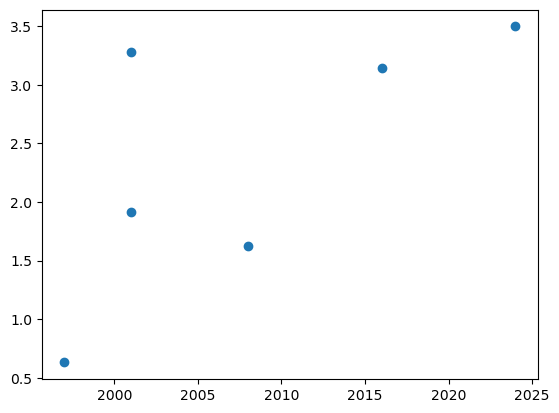

In [20]:
plt.figure()
plt.scatter(year_array, sep_array)
plt.show()

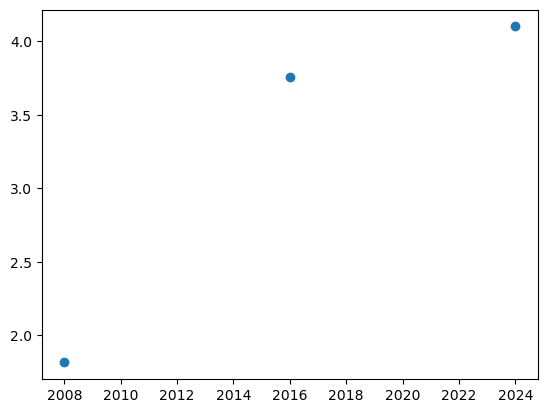

In [21]:
plt.figure()
plt.scatter(year_array2, sep_array2)
plt.show()

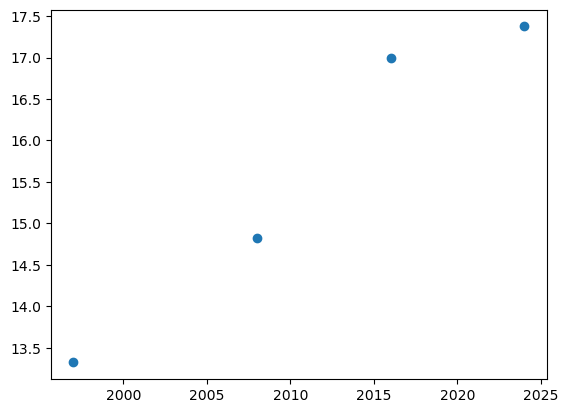

In [22]:
plt.figure()
plt.scatter(year_array3, sep_array3)
plt.show()

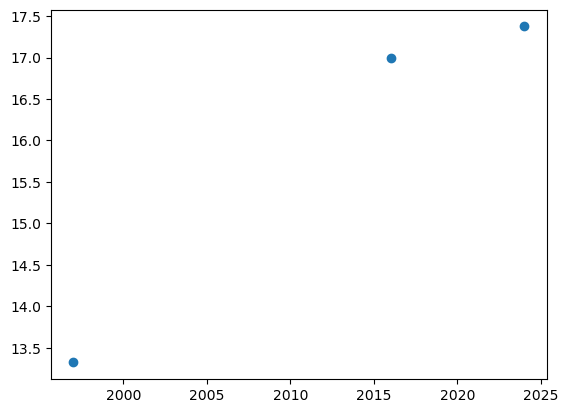

In [23]:
plt.figure()
plt.scatter(year_array4, sep_array4)
plt.show()

In [24]:
ecoord08.ra.arcsec

0.45

/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/894388969.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/894388969.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(hourstring(t) for t in yticks)


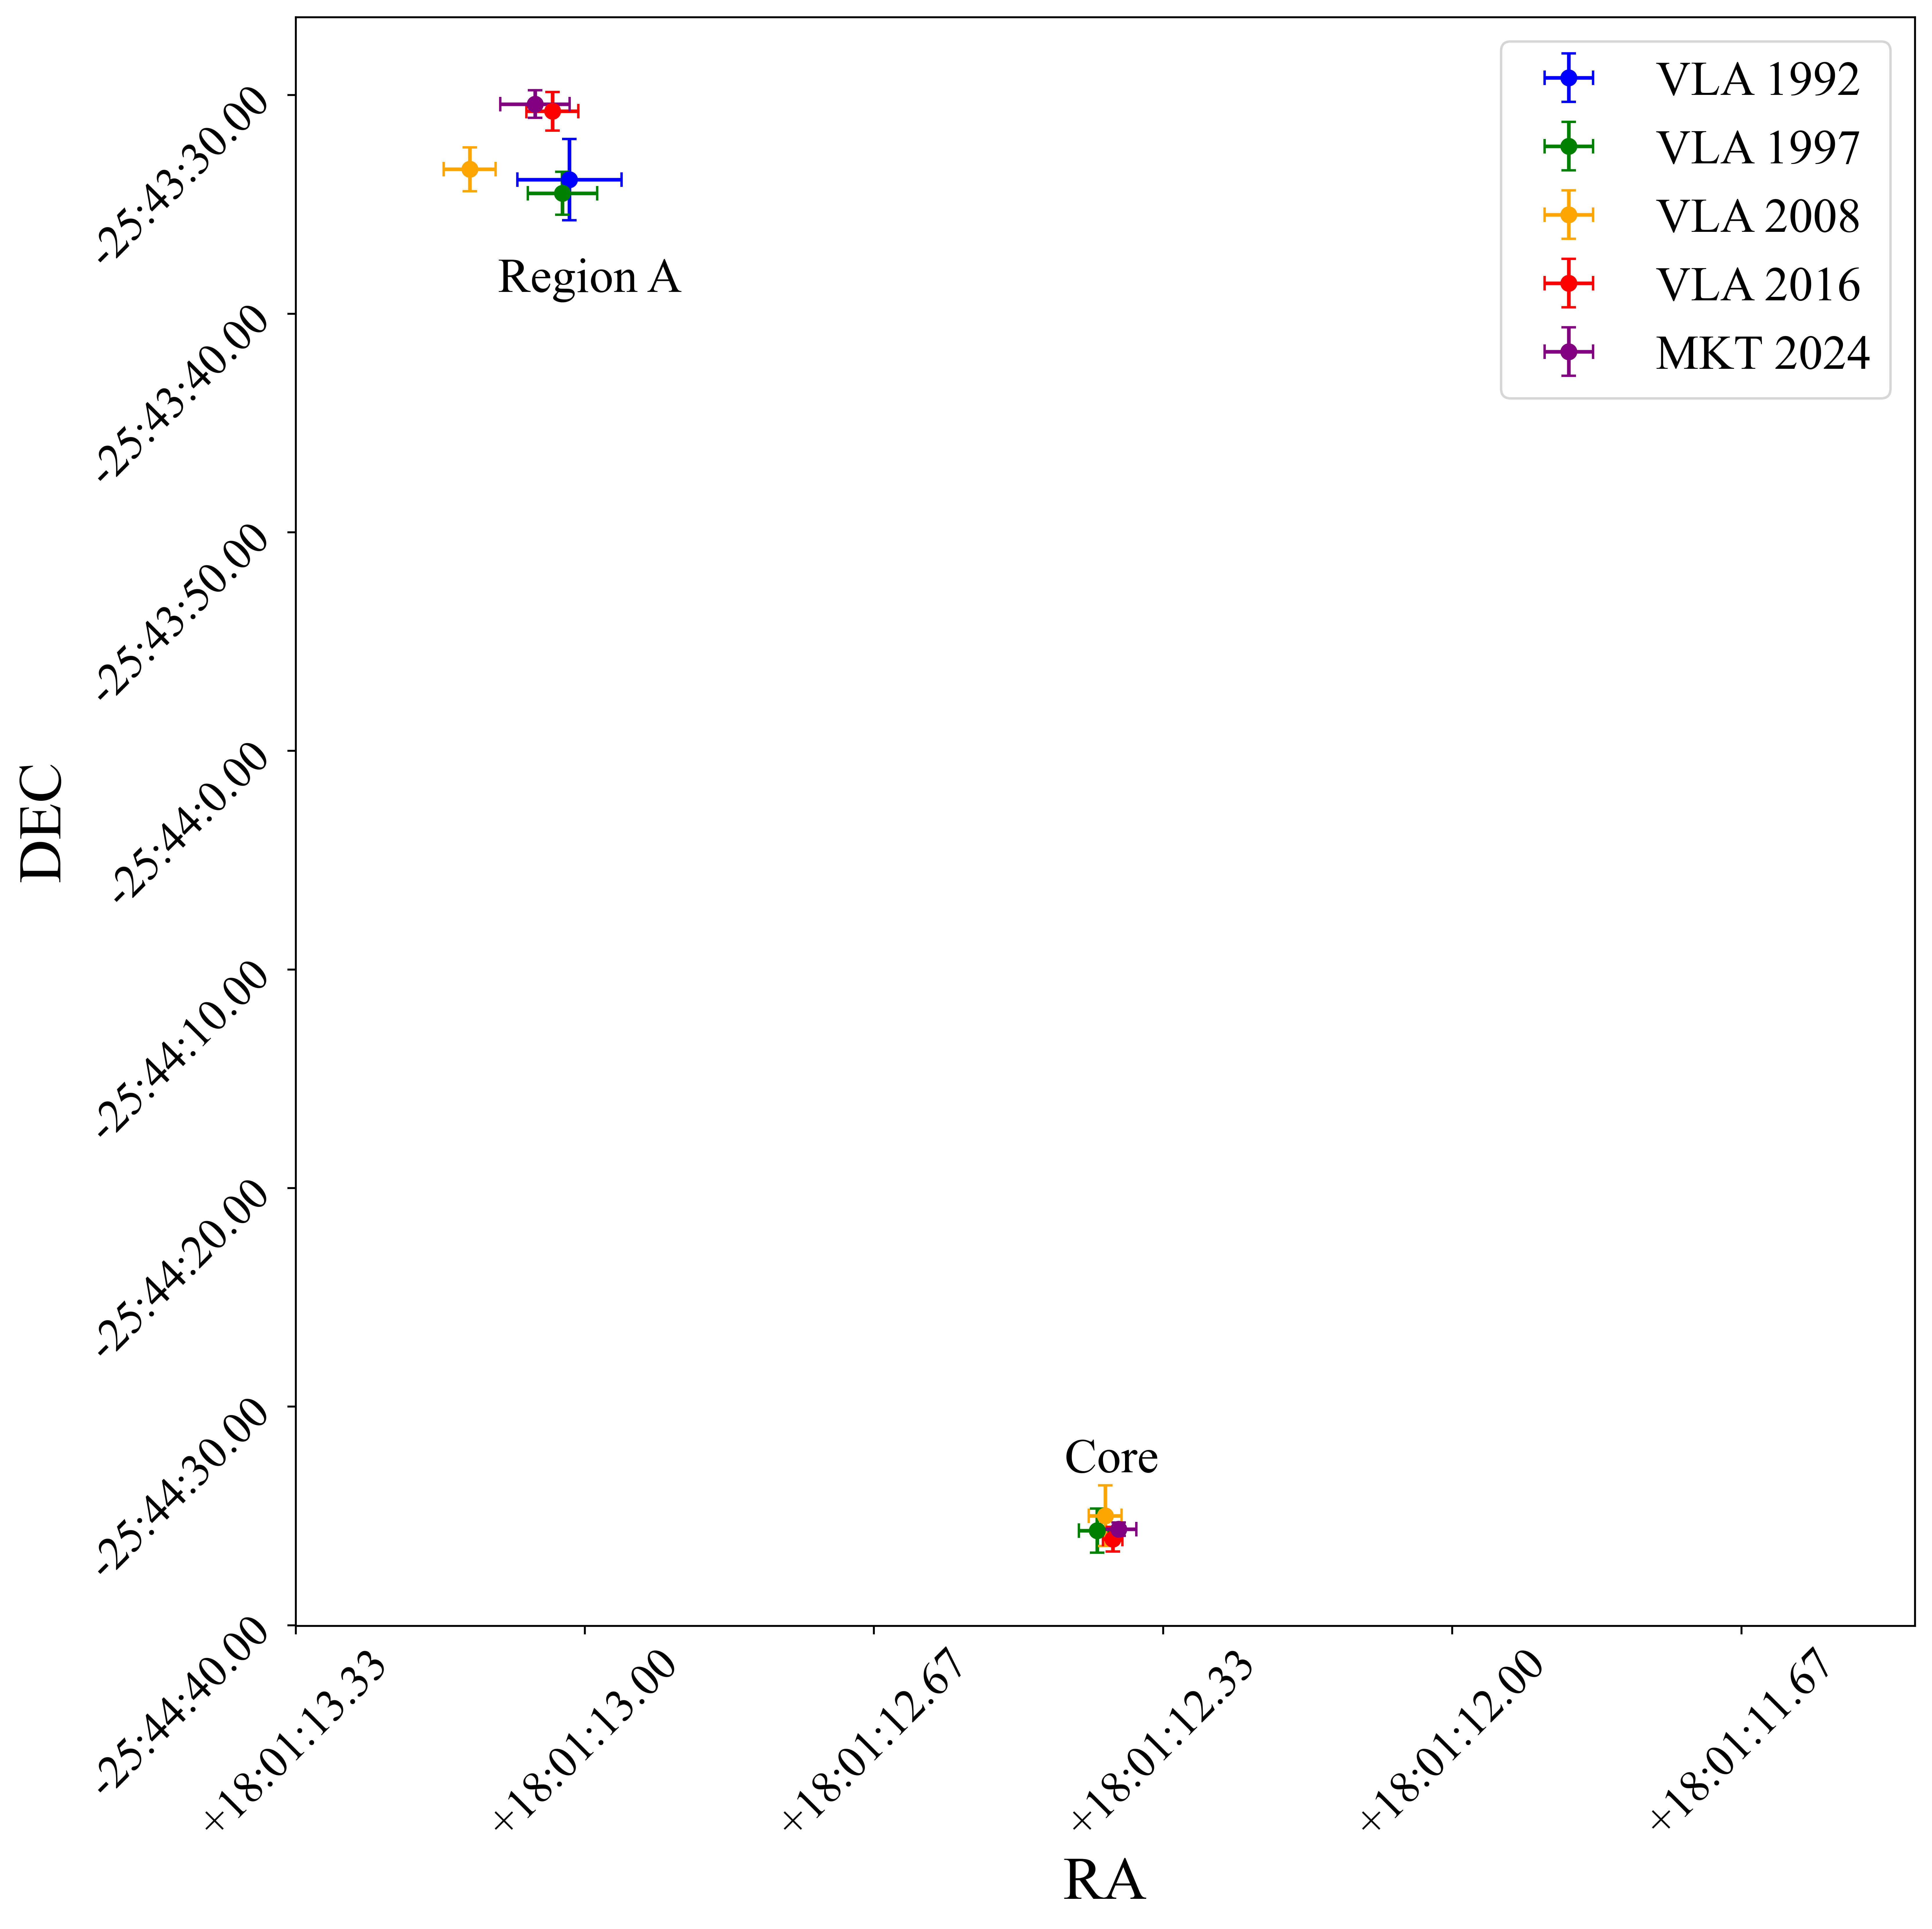

In [25]:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
})

plt.figure(figsize=(12,12), dpi=600)
plt.errorbar(coord92.ra.arcsec, coord92.dec.arcsec, xerr=ecoord92.ra.arcsec, yerr=ecoord92.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 1992', color='blue')
#plt.errorbar(coord92_2.ra.arcsec, coord92_2.dec.arcsec, xerr=ecoord92_2.ra.arcsec, yerr=ecoord92_2.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 1992 (down)')
plt.errorbar(coord97.ra.arcsec, coord97.dec.arcsec, xerr=ecoord97.ra.arcsec, yerr=ecoord97.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 1997', color='green')
#plt.errorbar(coord01_1.ra.arcsec, coord01_1.dec.arcsec, xerr=ecoord01_1.ra.arcsec, yerr=ecoord01_1.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 2001', c='lightgray')
#plt.errorbar(coord01_2.ra.arcsec, coord01_2.dec.arcsec, xerr=ecoord01_2.ra.arcsec, yerr=ecoord01_2.dec.arcsec, capsize=3, marker='o', linestyle='', c='lightgray')
plt.errorbar(coord08.ra.arcsec, coord08.dec.arcsec, xerr=ecoord08.ra.arcsec, yerr=ecoord08.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 2008', color='orange')
plt.errorbar(coord16.ra.arcsec, coord16.dec.arcsec, xerr=ecoord16.ra.arcsec, yerr=ecoord16.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 2016', color='red')
plt.errorbar(coord24.ra.arcsec, coord24.dec.arcsec, xerr=ecoord24.ra.arcsec, yerr=ecoord24.dec.arcsec, capsize=3, marker='o', linestyle='', label='MKT 2024', color='purple')
plt.errorbar(ccoord97.ra.arcsec, ccoord97.dec.arcsec, xerr=cecoord97.ra.arcsec, yerr=cecoord97.dec.arcsec, capsize=3, marker='o', linestyle='', color='green')
#plt.errorbar(ccoord01.ra.arcsec, ccoord01.dec.arcsec, xerr=cecoord01.ra.arcsec, yerr=cecoord01.dec.arcsec, capsize=3, marker='o', linestyle='', color='lightgray')
plt.errorbar(ccoord08.ra.arcsec, ccoord08.dec.arcsec, xerr=cecoord08.ra.arcsec, yerr=cecoord08.dec.arcsec, capsize=3, marker='o', linestyle='', color='orange')
plt.errorbar(ccoord16.ra.arcsec, ccoord16.dec.arcsec, xerr=cecoord16.ra.arcsec, yerr=cecoord16.dec.arcsec, capsize=3, marker='o', linestyle='', color='red')
plt.errorbar(ccoord24.ra.arcsec, ccoord24.dec.arcsec, xerr=cecoord24.ra.arcsec, yerr=cecoord24.dec.arcsec, capsize=3, marker='o', linestyle='', color='purple')
plt.gca().invert_xaxis()
plt.xlim([973100, 973072])
plt.annotate('Region A', xy=(973096.5, -92619), fontsize=20)
plt.annotate('Core', xy=(973086.7, -92673), fontsize=20)
#plt.gca().invert_yaxis()
plt.gca().tick_params(labelsize=19)
xticks = plt.gca().get_xticks()
plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels(hourstring(t) for t in yticks)
#plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
#plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
plt.xlabel('RA', size=25)
plt.ylabel('DEC', size=25)
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.legend(fontsize=20)
plt.savefig('Positions_core_A.pdf', bbox_inches='tight')
plt.show()

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Arial"],
})

/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/1756673460.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/1756673460.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(hourstring(t) for t in yticks)


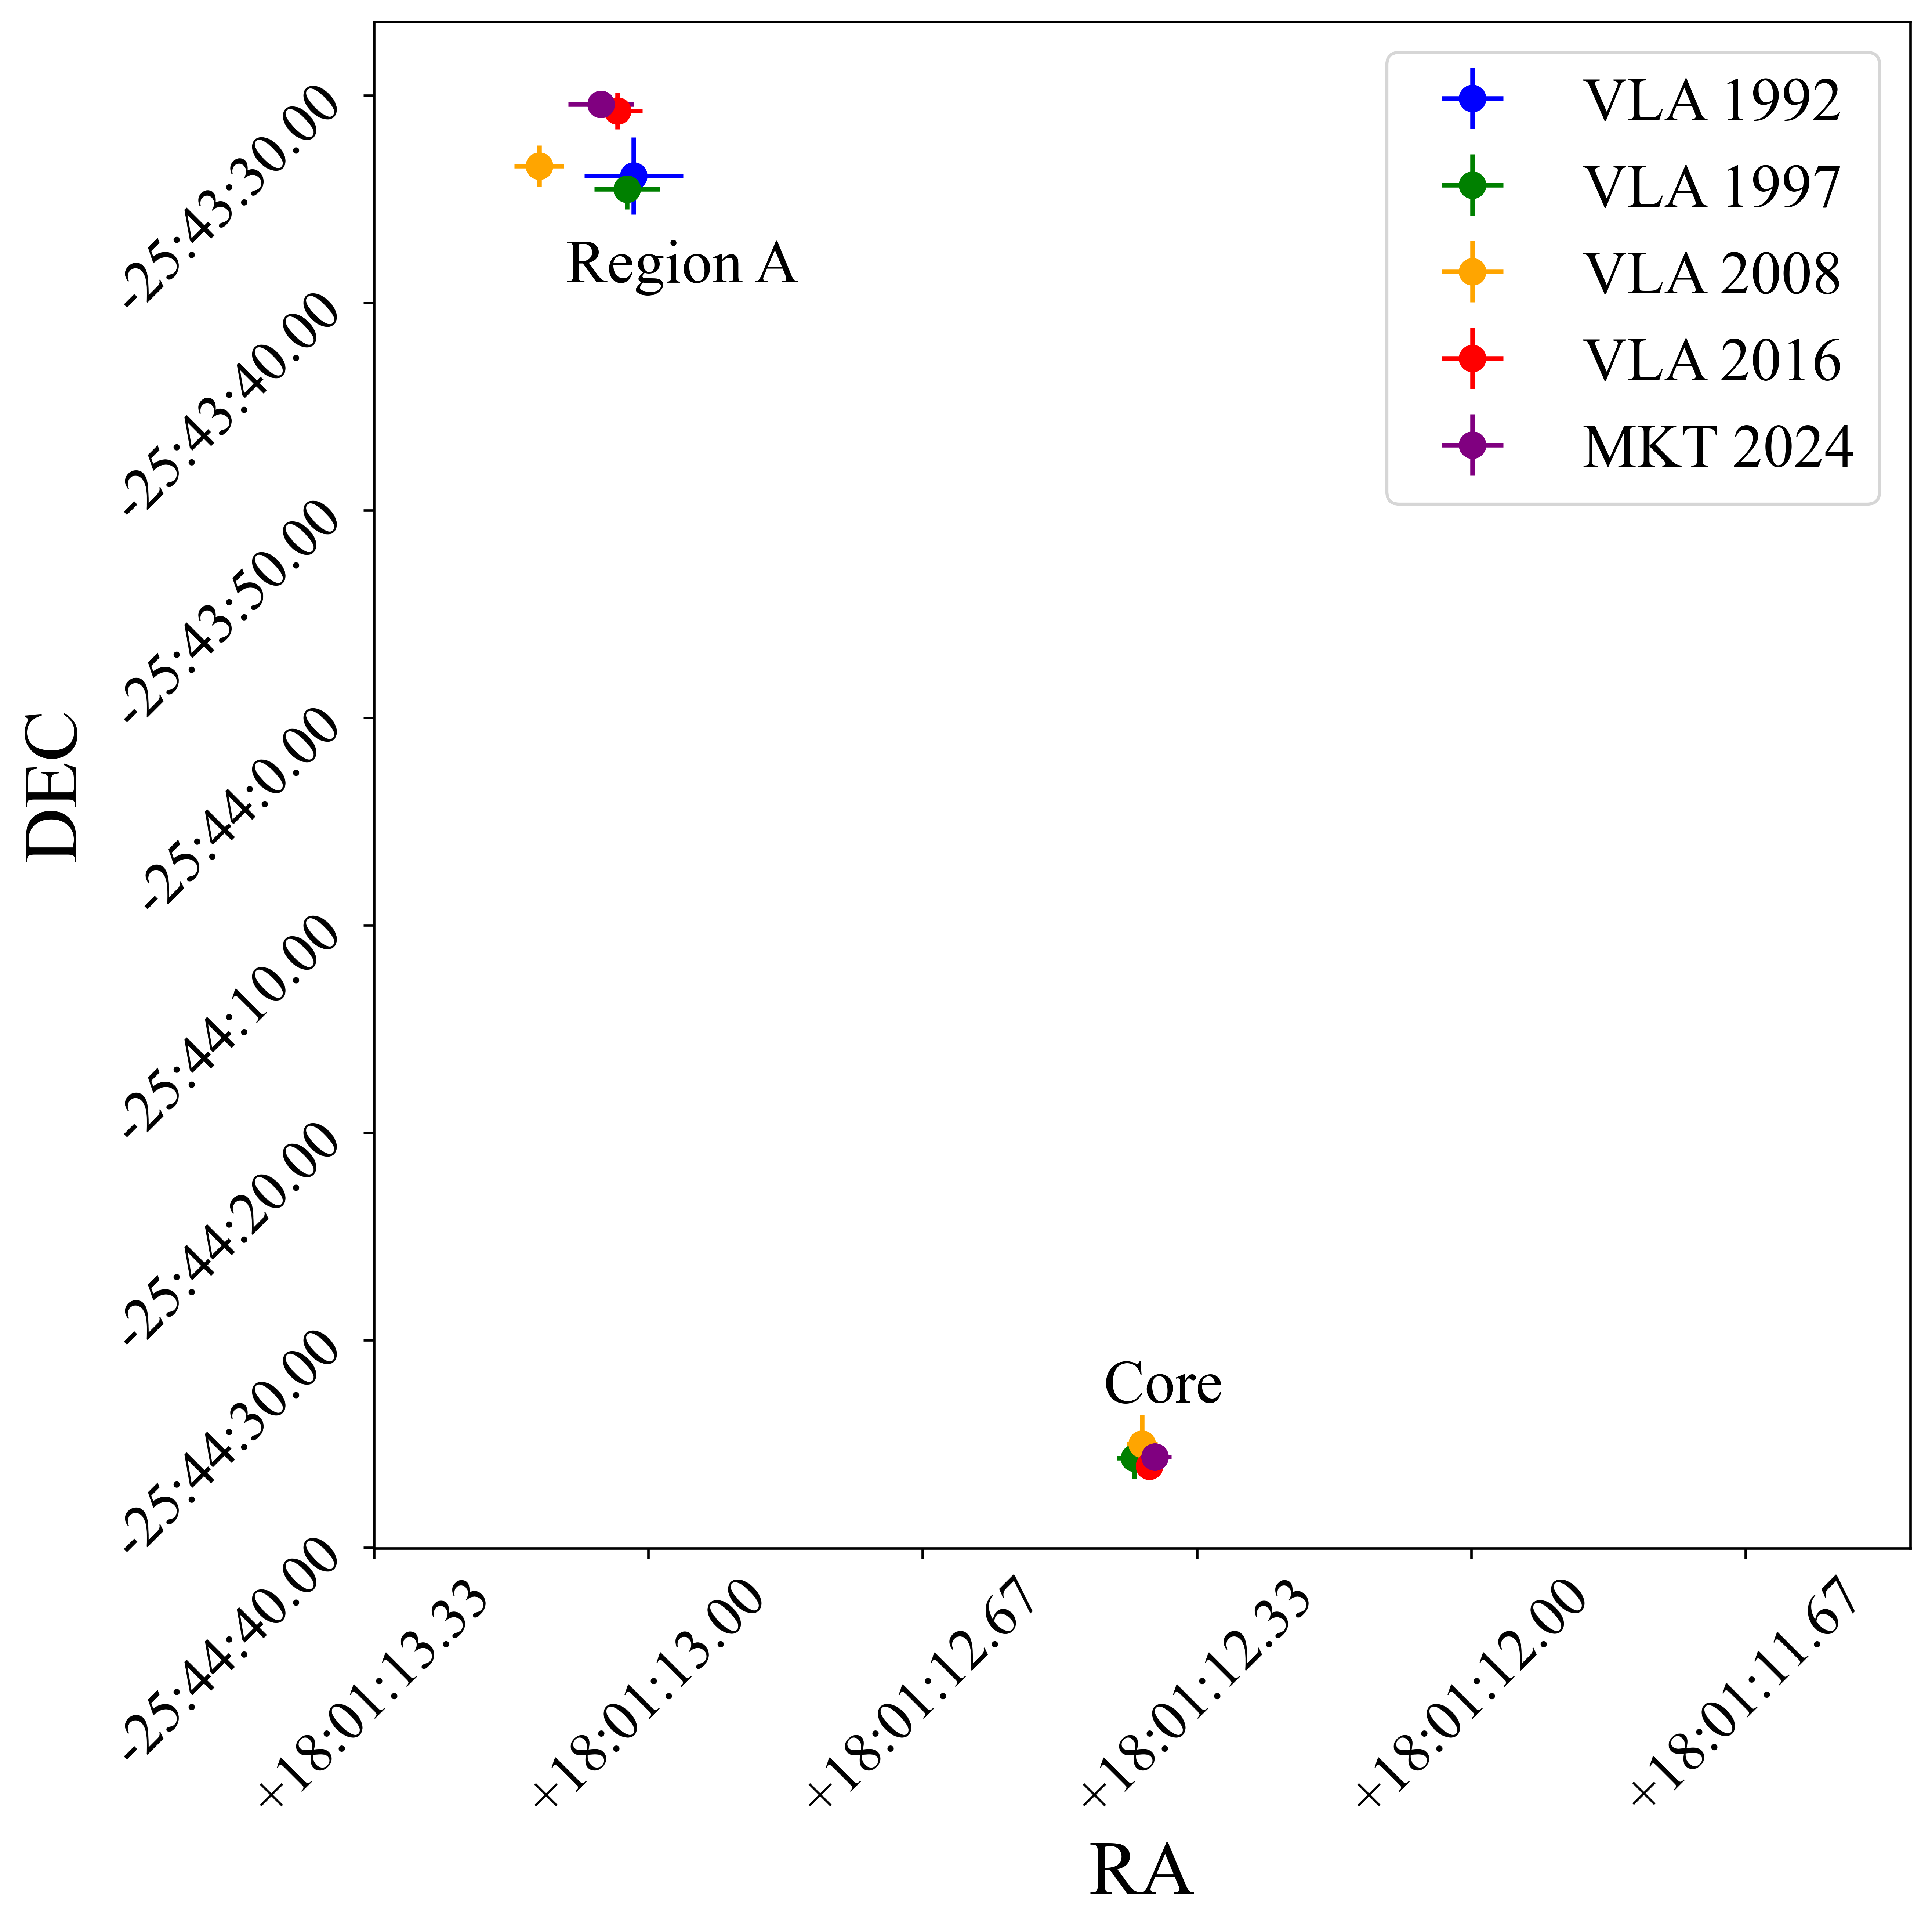

In [26]:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
})

plt.figure(figsize=(9,9), dpi=600)
plt.errorbar(coord92.ra.arcsec, coord92.dec.arcsec, xerr=ecoord92.ra.arcsec, yerr=ecoord92.dec.arcsec, markersize=8, marker='o', linestyle='', label='VLA 1992', color='blue')
#plt.errorbar(coord92_2.ra.arcsec, coord92_2.dec.arcsec, xerr=ecoord92_2.ra.arcsec, yerr=ecoord92_2.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 1992 (down)')
plt.errorbar(coord97.ra.arcsec, coord97.dec.arcsec, xerr=ecoord97.ra.arcsec, yerr=ecoord97.dec.arcsec, markersize=8, marker='o', linestyle='', label='VLA 1997', color='green')
#plt.errorbar(coord01_1.ra.arcsec, coord01_1.dec.arcsec, xerr=ecoord01_1.ra.arcsec, yerr=ecoord01_1.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 2001', c='lightgray')
#plt.errorbar(coord01_2.ra.arcsec, coord01_2.dec.arcsec, xerr=ecoord01_2.ra.arcsec, yerr=ecoord01_2.dec.arcsec, capsize=3, marker='o', linestyle='', c='lightgray')
plt.errorbar(coord08.ra.arcsec, coord08.dec.arcsec, xerr=ecoord08.ra.arcsec, yerr=ecoord08.dec.arcsec, markersize=8, marker='o', linestyle='', label='VLA 2008', color='orange')
plt.errorbar(coord16.ra.arcsec, coord16.dec.arcsec, xerr=ecoord16.ra.arcsec, yerr=ecoord16.dec.arcsec, markersize=8, marker='o', linestyle='', label='VLA 2016', color='red')
plt.errorbar(coord24.ra.arcsec, coord24.dec.arcsec, xerr=ecoord24.ra.arcsec, yerr=ecoord24.dec.arcsec, markersize=8, marker='o', linestyle='', label='MKT 2024', color='purple')
plt.errorbar(ccoord97.ra.arcsec, ccoord97.dec.arcsec, xerr=cecoord97.ra.arcsec, yerr=cecoord97.dec.arcsec, markersize=8, marker='o', linestyle='', color='green')
#plt.errorbar(ccoord01.ra.arcsec, ccoord01.dec.arcsec, xerr=cecoord01.ra.arcsec, yerr=cecoord01.dec.arcsec, capsize=3, marker='o', linestyle='', color='lightgray')
plt.errorbar(ccoord08.ra.arcsec, ccoord08.dec.arcsec, xerr=cecoord08.ra.arcsec, yerr=cecoord08.dec.arcsec, markersize=8, marker='o', linestyle='', color='orange')
plt.errorbar(ccoord16.ra.arcsec, ccoord16.dec.arcsec, xerr=cecoord16.ra.arcsec, yerr=cecoord16.dec.arcsec, markersize=8, marker='o', linestyle='', color='red')
plt.errorbar(ccoord24.ra.arcsec, ccoord24.dec.arcsec, xerr=cecoord24.ra.arcsec, yerr=cecoord24.dec.arcsec, markersize=8, marker='o', linestyle='', color='purple')
plt.gca().invert_xaxis()
plt.xlim([973100, 973072])
plt.annotate('Region A', xy=(973096.5, -92619), fontsize=20)
plt.annotate('Core', xy=(973086.7, -92673), fontsize=20)
#plt.gca().invert_yaxis()
plt.gca().tick_params(labelsize=19)
xticks = plt.gca().get_xticks()
plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels(hourstring(t) for t in yticks)
#plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
#plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
plt.xlabel('RA', size=25)
plt.ylabel('DEC', size=25)
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.legend(fontsize=20)
plt.savefig('Positions_core_A_small.pdf', bbox_inches='tight')
plt.show()

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Arial"],
})

/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/1500396458.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/1500396458.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(hourstring(t) for t in yticks)


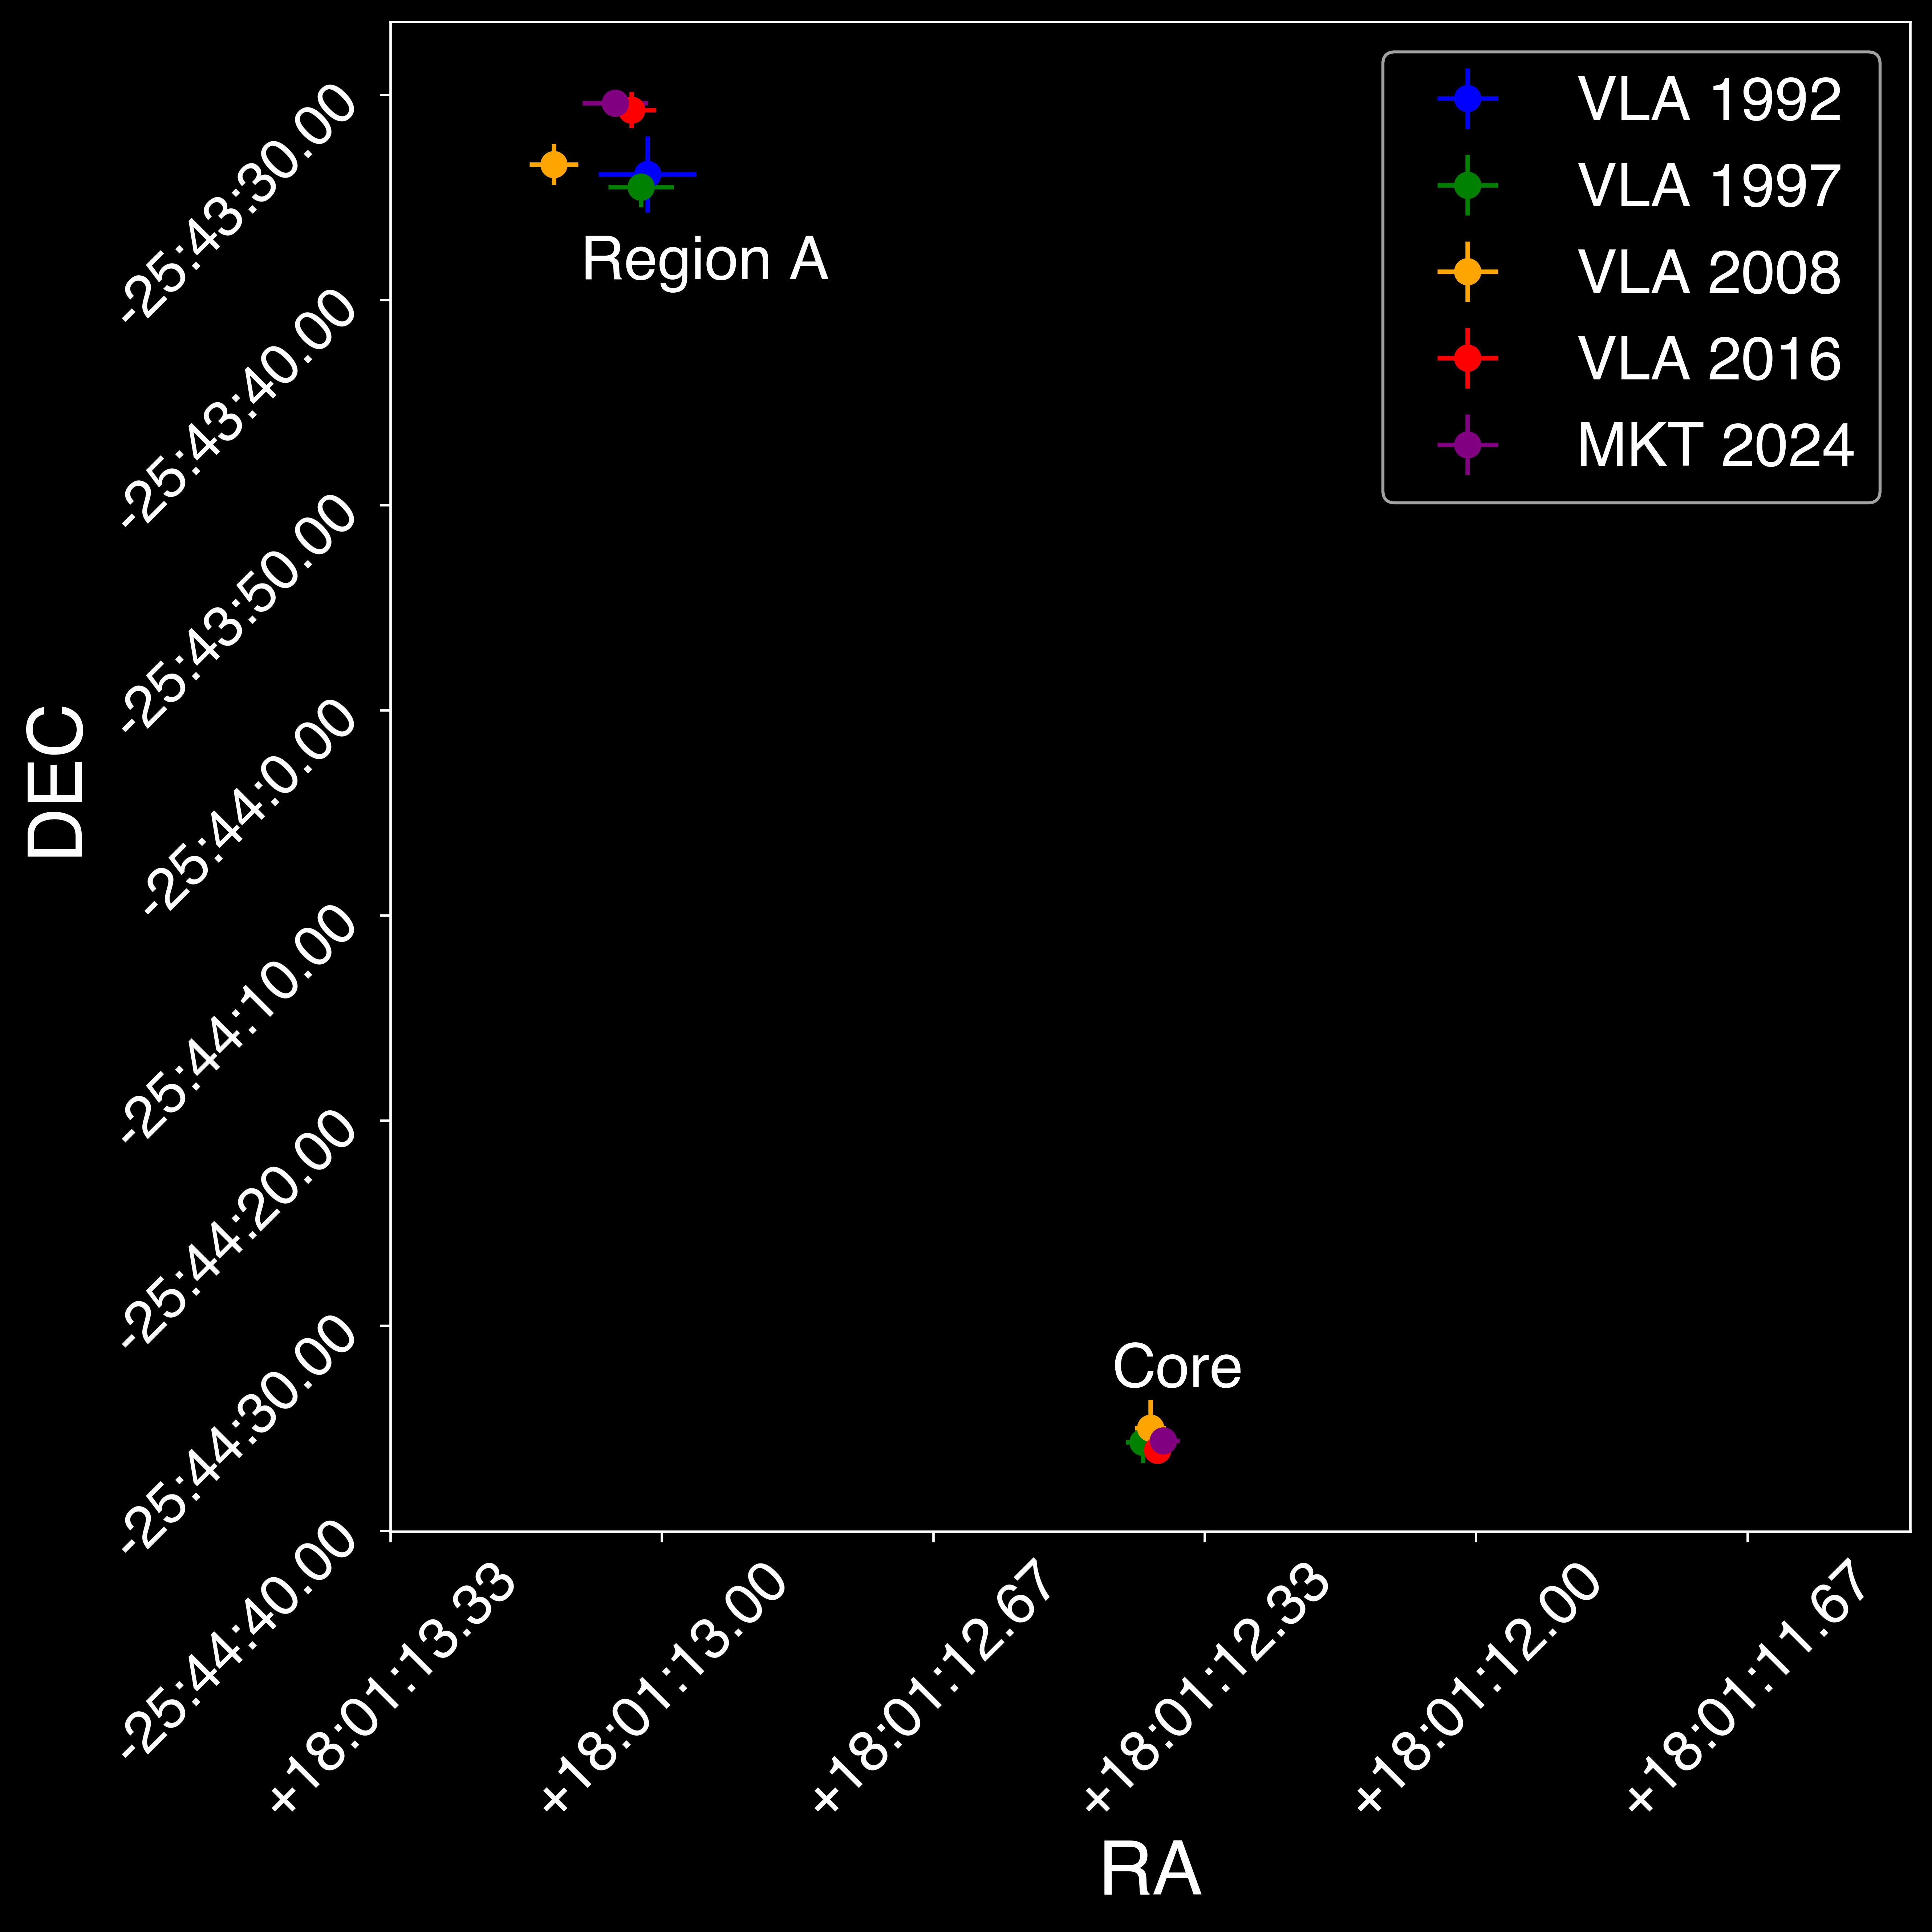

In [101]:
plt.style.use('dark_background')

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Helvetica"],
})

plt.figure(figsize=(9,9), dpi=600)
plt.errorbar(coord92.ra.arcsec, coord92.dec.arcsec, xerr=ecoord92.ra.arcsec, yerr=ecoord92.dec.arcsec, markersize=8, marker='o', linestyle='', label='VLA 1992', color='blue')
#plt.errorbar(coord92_2.ra.arcsec, coord92_2.dec.arcsec, xerr=ecoord92_2.ra.arcsec, yerr=ecoord92_2.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 1992 (down)')
plt.errorbar(coord97.ra.arcsec, coord97.dec.arcsec, xerr=ecoord97.ra.arcsec, yerr=ecoord97.dec.arcsec, markersize=8, marker='o', linestyle='', label='VLA 1997', color='green')
#plt.errorbar(coord01_1.ra.arcsec, coord01_1.dec.arcsec, xerr=ecoord01_1.ra.arcsec, yerr=ecoord01_1.dec.arcsec, capsize=0, marker='o', linestyle='', label='VLA 2001', c='lightgray')
#plt.errorbar(coord01_2.ra.arcsec, coord01_2.dec.arcsec, xerr=ecoord01_2.ra.arcsec, yerr=ecoord01_2.dec.arcsec, capsize=0, marker='o', linestyle='', c='lightgray')
plt.errorbar(coord08.ra.arcsec, coord08.dec.arcsec, xerr=ecoord08.ra.arcsec, yerr=ecoord08.dec.arcsec, markersize=8, marker='o', linestyle='', label='VLA 2008', color='orange')
plt.errorbar(coord16.ra.arcsec, coord16.dec.arcsec, xerr=ecoord16.ra.arcsec, yerr=ecoord16.dec.arcsec, markersize=8, marker='o', linestyle='', label='VLA 2016', color='red')
plt.errorbar(coord24.ra.arcsec, coord24.dec.arcsec, xerr=ecoord24.ra.arcsec, yerr=ecoord24.dec.arcsec, markersize=8, marker='o', linestyle='', label='MKT 2024', color='purple')
plt.errorbar(ccoord97.ra.arcsec, ccoord97.dec.arcsec, xerr=cecoord97.ra.arcsec, yerr=cecoord97.dec.arcsec, markersize=8, marker='o', linestyle='', color='green')
#plt.errorbar(ccoord01.ra.arcsec, ccoord01.dec.arcsec, xerr=cecoord01.ra.arcsec, yerr=cecoord01.dec.arcsec, capsize=3, marker='o', linestyle='', color='lightgray')
plt.errorbar(ccoord08.ra.arcsec, ccoord08.dec.arcsec, xerr=cecoord08.ra.arcsec, yerr=cecoord08.dec.arcsec, markersize=8, marker='o', linestyle='', color='orange')
plt.errorbar(ccoord16.ra.arcsec, ccoord16.dec.arcsec, xerr=cecoord16.ra.arcsec, yerr=cecoord16.dec.arcsec, markersize=8, marker='o', linestyle='', color='red')
plt.errorbar(ccoord24.ra.arcsec, ccoord24.dec.arcsec, xerr=cecoord24.ra.arcsec, yerr=cecoord24.dec.arcsec, markersize=8, marker='o', linestyle='', color='purple')
plt.gca().invert_xaxis()
plt.xlim([973100, 973072])
plt.annotate('Region A', xy=(973096.5, -92619), fontsize=20)
plt.annotate('Core', xy=(973086.7, -92673), fontsize=20)
#plt.gca().invert_yaxis()
plt.gca().tick_params(labelsize=19)
xticks = plt.gca().get_xticks()
plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels(hourstring(t) for t in yticks)
#plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
#plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
plt.xlabel('RA', size=25)
plt.ylabel('DEC', size=25)
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.legend(fontsize=20)
plt.savefig('Positions_core_A_small.pdf', bbox_inches='tight')
plt.show()

plt.style.use('default')

In [27]:
plt.figure(figsize=(14,14), dpi=600)
plt.errorbar(coord92.ra.arcsec, coord92.dec.arcsec, xerr=ecoord92.ra.arcsec, yerr=ecoord92.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 1992', color='blue')
#plt.errorbar(coord92_2.ra.arcsec, coord92_2.dec.arcsec, xerr=ecoord92_2.ra.arcsec, yerr=ecoord92_2.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 1992 (down)')
plt.errorbar(coord97.ra.arcsec, coord97.dec.arcsec, xerr=ecoord97.ra.arcsec, yerr=ecoord97.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 1997', color='green')
plt.errorbar(coord01_1.ra.arcsec, coord01_1.dec.arcsec, xerr=ecoord01_1.ra.arcsec, yerr=ecoord01_1.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 2001', c='gray')
plt.errorbar(coord01_2.ra.arcsec, coord01_2.dec.arcsec, xerr=ecoord01_2.ra.arcsec, yerr=ecoord01_2.dec.arcsec, capsize=3, marker='o', linestyle='', c='gray')
plt.errorbar(coord08.ra.arcsec, coord08.dec.arcsec, xerr=ecoord08.ra.arcsec, yerr=ecoord08.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 2008', color='orange')
plt.errorbar(coord16.ra.arcsec, coord16.dec.arcsec, xerr=ecoord16.ra.arcsec, yerr=ecoord16.dec.arcsec, capsize=3, marker='o', linestyle='', label='VLA 2016', color='red')
plt.errorbar(coord24.ra.arcsec, coord24.dec.arcsec, xerr=ecoord24.ra.arcsec, yerr=ecoord24.dec.arcsec, capsize=3, marker='o', linestyle='', label='MK 2024', color='purple')
plt.errorbar(ccoord97.ra.arcsec, ccoord97.dec.arcsec, xerr=cecoord97.ra.arcsec, yerr=cecoord97.dec.arcsec, capsize=3, marker='o', linestyle='', color='green')
plt.errorbar(ccoord01.ra.arcsec, ccoord01.dec.arcsec, xerr=cecoord01.ra.arcsec, yerr=cecoord01.dec.arcsec, capsize=3, marker='o', linestyle='', color='gray')
plt.errorbar(ccoord08.ra.arcsec, ccoord08.dec.arcsec, xerr=cecoord08.ra.arcsec, yerr=cecoord08.dec.arcsec, capsize=3, marker='o', linestyle='', color='orange')
plt.errorbar(ccoord16.ra.arcsec, ccoord16.dec.arcsec, xerr=cecoord16.ra.arcsec, yerr=cecoord16.dec.arcsec, capsize=3, marker='o', linestyle='', color='red')
plt.errorbar(ccoord24.ra.arcsec, ccoord24.dec.arcsec, xerr=cecoord24.ra.arcsec, yerr=cecoord24.dec.arcsec, capsize=3, marker='o', linestyle='', color='purple')
plt.gca().invert_xaxis()
#plt.gca().invert_yaxis()
plt.gca().tick_params(labelsize=14)
xticks = plt.gca().get_xticks()
#plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
yticks = plt.gca().get_yticks()
#plt.gca().set_yticklabels(hourstring(t) for t in yticks)
#plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
#plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
plt.annotate('Region A', xy=(973096.5, -92619), fontsize=14)
plt.annotate('Core', xy=(973086.7, -92673), fontsize=14)
plt.xlim([973100, 973072])
#plt.ylim([-92700, -92600])
plt.xlabel('RA', size=20)
plt.ylabel('DEC', size=20)
plt.xticks(rotation=45)
plt.yticks(rotation=45)
#plt.gca().yaxis.set_major_locator(ticker.MultipleLocator(20))
plt.legend(fontsize=14)
plt.show()

In [28]:
years = np.array([1997, 2008, 2016, 2024])
years2 = np.array([1997, 2016, 2024])
years3 = np.array([1992, 1997, 2008, 2016, 2024])
years4 = np.array([1992, 1997, 2016, 2024])
ras = np.array([coord97.ra.arcsec, coord08.ra.arcsec, coord16.ra.arcsec, coord24.ra.arcsec])
ras2 = np.array([coord97.ra.arcsec, coord16.ra.arcsec, coord24.ra.arcsec])
ras3 = np.array([coord92_2.ra.arcsec, coord97.ra.arcsec, coord08.ra.arcsec, coord16.ra.arcsec, coord24.ra.arcsec])
ras4 = np.array([coord92_2.ra.arcsec, coord97.ra.arcsec, coord16.ra.arcsec, coord24.ra.arcsec])
eras = np.array([ecoord97.ra.arcsec, ecoord08.ra.arcsec, ecoord16.ra.arcsec, ecoord24.ra.arcsec])
eras2 = np.array([ecoord97.ra.arcsec, ecoord16.ra.arcsec, ecoord24.ra.arcsec])
decs = np.array([coord97.dec.arcsec, coord08.dec.arcsec, coord16.dec.arcsec, coord24.dec.arcsec])
decs2 = np.array([coord97.dec.arcsec, coord16.dec.arcsec, coord24.dec.arcsec])
decs3 = np.array([coord92_2.dec.arcsec, coord97.dec.arcsec, coord08.dec.arcsec, coord16.dec.arcsec, coord24.dec.arcsec])
decs4 = np.array([coord92_2.dec.arcsec, coord97.dec.arcsec, coord16.dec.arcsec, coord24.dec.arcsec])
edecs = np.array([ecoord97.dec.arcsec, ecoord08.dec.arcsec, ecoord16.dec.arcsec, ecoord24.dec.arcsec])
edecs2 = np.array([ecoord97.dec.arcsec, ecoord16.dec.arcsec, ecoord24.dec.arcsec])

In [29]:
def linear(x, m, q):
    return m*x+q

In [30]:
#vfit_ra, vcov_ra = curve_fit(linear, years2, ras2, sigma=eras2)
#vfit_dec, vcov_dec = curve_fit(linear, years2, decs2, sigma=edecs2)

vfit_ra, vcov_ra = curve_fit(linear, years, ras)
vfit_dec, vcov_dec = curve_fit(linear, years, decs)

vtot_fit = np.sqrt(vfit_ra[0]**2+vfit_dec[0]**2)

vfit2_ra, vcov2_ra = curve_fit(linear, years2, ras2)
vfit2_dec, vcov2_dec = curve_fit(linear, years2, decs2)

vtot2_fit = np.sqrt(vfit2_ra[0]**2+vfit2_dec[0]**2)

vfit3_ra, vcov3_ra = curve_fit(linear, years3, ras3)
vfit3_dec, vcov3_dec = curve_fit(linear, years3, decs3)

vtot3_fit = np.sqrt(vfit3_ra[0]**2+vfit3_dec[0]**2)

vfit4_ra, vcov4_ra = curve_fit(linear, years4, ras4)
vfit4_dec, vcov4_dec = curve_fit(linear, years4, decs4)

vtot4_fit = np.sqrt(vfit4_ra[0]**2+vfit4_dec[0]**2)

In [31]:
vfit_ra[0]

0.004172007524368126

In [32]:
vfit_dec[0]

0.1661844231185805

In [33]:
vtot_fit

0.1662367833364168

In [34]:
def ra_formatter(rasec, pos):
    coord = SkyCoord(ra=rasec*u.second, dec=0*u.deg)
    return coord.re.to_string(uniy=u.hour, sep=':')

/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/101112191.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/101112191.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(hourstring(t) for t in yticks)


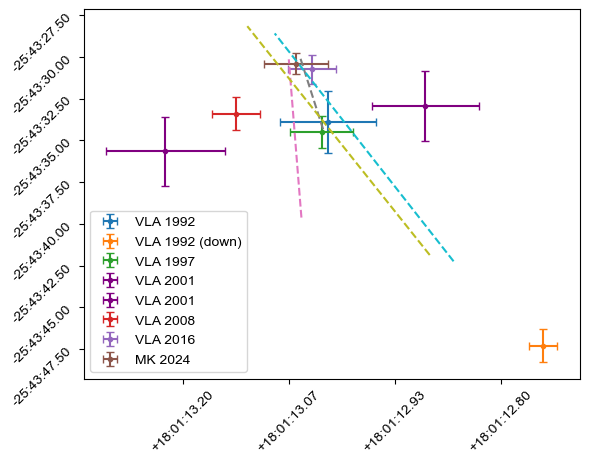

In [35]:
year_fit = np.linspace(min(years-30), max(years), 100)
ra_fit = linear(year_fit, *vfit_ra)
dec_fit = linear(year_fit, *vfit_dec)

year2_fit = np.linspace(min(years2), max(years2), 100)
ra2_fit = linear(year2_fit, *vfit2_ra)
dec2_fit = linear(year2_fit, *vfit2_dec)

year3_fit = np.linspace(min(years3), max(years3), 100)
ra3_fit = linear(year3_fit, *vfit3_ra)
dec3_fit = linear(year3_fit, *vfit3_dec)

year4_fit = np.linspace(min(years4), max(years4), 100)
ra4_fit = linear(year4_fit, *vfit4_ra)
dec4_fit = linear(year4_fit, *vfit4_dec)

plt.figure()
plt.errorbar(coord92.ra.arcsec, coord92.dec.arcsec, xerr=ecoord92.ra.arcsec, yerr=ecoord92.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 1992')
plt.errorbar(coord92_2.ra.arcsec, coord92_2.dec.arcsec, xerr=ecoord92_2.ra.arcsec, yerr=ecoord92_2.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 1992 (down)')
plt.errorbar(coord97.ra.arcsec, coord97.dec.arcsec, xerr=ecoord97.ra.arcsec, yerr=ecoord97.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 1997')
plt.errorbar(coord01_1.ra.arcsec, coord01_1.dec.arcsec, xerr=ecoord01_1.ra.arcsec, yerr=ecoord01_1.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 2001', c='purple')
plt.errorbar(coord01_2.ra.arcsec, coord01_2.dec.arcsec, xerr=ecoord01_2.ra.arcsec, yerr=ecoord01_2.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 2001', c='purple')
plt.errorbar(coord08.ra.arcsec, coord08.dec.arcsec, xerr=ecoord08.ra.arcsec, yerr=ecoord08.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 2008')
plt.errorbar(coord16.ra.arcsec, coord16.dec.arcsec, xerr=ecoord16.ra.arcsec, yerr=ecoord16.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 2016')
plt.errorbar(coord24.ra.arcsec, coord24.dec.arcsec, xerr=ecoord24.ra.arcsec, yerr=ecoord24.dec.arcsec, capsize=3, marker='.', linestyle='', label='MK 2024')
plt.plot(ra_fit, dec_fit, linestyle='--')
plt.plot(ra2_fit, dec2_fit, linestyle='--')
plt.plot(ra3_fit, dec3_fit, linestyle='--')
plt.plot(ra4_fit, dec4_fit, linestyle='--')
plt.gca().invert_xaxis()
#plt.gca().invert_yaxis
xticks = plt.gca().get_xticks()
plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels(hourstring(t) for t in yticks)
#plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
#plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
xlim = plt.gca().get_xlim()
ylim = plt.gca().get_ylim()
xrange = xlim[1] - xlim[0]
yrange = ylim[1]-ylim[0]
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.legend()
plt.show()

In [36]:
dist = 8.5*1e3 #parsec
dist10kpc = 0.85
incl = 61
eincl = 2

vno = 4.74*(vtot_fit/np.sin(incl*np.pi/180))*dist

In [37]:
vno

7657.819674027499

In [38]:
dist10kpc

0.85

In [39]:
pc_km = 3.086e13
v = (vtot_fit/np.sin(incl*np.pi/180))*(0.048*dist10kpc*pc_km)/(365*24*3600)
v2 = (vtot2_fit/np.sin(incl*np.pi/180))*(0.048*dist10kpc*pc_km)/(365*24*3600)
v3 = (vtot3_fit/np.sin(incl*np.pi/180))*(0.048*dist10kpc*pc_km)/(365*24*3600)
v4 = (vtot4_fit/np.sin(incl*np.pi/180))*(0.048*dist10kpc*pc_km)/(365*24*3600)

In [40]:
print(v, v2, v3, v4)

7588.524592043125 7317.549112022283 20140.82361007312 20040.55154892155


In [41]:
print(v/c, v2/c, v3/c, v4/c)

0.025295081973477084 0.02439183037340761 0.06713607870024373 0.06680183849640517


In [42]:
print(np.sqrt(1/(1-(v/c)**2)), np.sqrt(1/(1-(v2/c)**2)), np.sqrt(1/(1-(v3/c)**2)), np.sqrt(1/(1-(v4/c)**2)))

1.0003200741916993 1.000297613502476 1.002261273508229 1.002238738359155


/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/2016018887.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/2016018887.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(hourstring(t) for t in yticks)


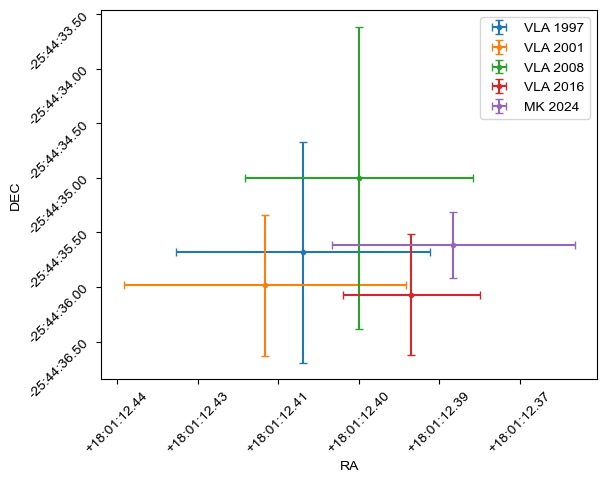

In [43]:
plt.figure()
plt.errorbar(ccoord97.ra.arcsec, ccoord97.dec.arcsec, xerr=cecoord97.ra.arcsec, yerr=cecoord97.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 1997')
plt.errorbar(ccoord01.ra.arcsec, ccoord01.dec.arcsec, xerr=cecoord01.ra.arcsec, yerr=cecoord01.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 2001')
plt.errorbar(ccoord08.ra.arcsec, ccoord08.dec.arcsec, xerr=cecoord08.ra.arcsec, yerr=cecoord08.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 2008')
plt.errorbar(ccoord16.ra.arcsec, ccoord16.dec.arcsec, xerr=cecoord16.ra.arcsec, yerr=cecoord16.dec.arcsec, capsize=3, marker='.', linestyle='', label='VLA 2016')
plt.errorbar(ccoord24.ra.arcsec, ccoord24.dec.arcsec, xerr=cecoord24.ra.arcsec, yerr=cecoord24.dec.arcsec, capsize=3, marker='.', linestyle='', label='MK 2024')
plt.gca().invert_xaxis()
#plt.gca().invert_yaxis()
xticks = plt.gca().get_xticks()
plt.gca().set_xticklabels(hourstring(t/15) for t in xticks)
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels(hourstring(t) for t in yticks)
#plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
#plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('%.6f'))
xlim2 = plt.gca().get_xlim()
ylim2 = plt.gca().get_ylim()
xcenter = (xlim2[0]+xlim2[1])/2
ycenter = (ylim2[0]+ylim2[1])/2
#plt.gca().set_xlim(xcenter-xrange/2, xcenter+xrange/2)
#plt.gca().set_ylim(ycenter-yrange/2, ycenter+yrange/2)
plt.xlabel('RA')
plt.ylabel('DEC')
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.legend()
plt.show()

### CM-based estimate for bright spot velocity

In [44]:
def velocity_fit(year_array, ra_array, dec_array, dist10=0.85, incl=61):
    vfit_ra, vcov_ra = curve_fit(linear, year_array, ra_array)
    vfit_dec, vcov_dec = curve_fit(linear, year_array, dec_array)
    vtot_fit = np.sqrt(vfit_ra[0]**2+vfit_dec[0]**2)
    vkms = (vtot_fit/np.sin(incl*np.pi/180))*(0.048*dist10*pc_km)/(365*24*3600)
    return vkms

def velocity_ccm(coord92, coord97, coord08, coord16, coord24, dist10=0.85, incl=61, eincl=2, niter=5000):
    ra92_rand = np.random.uniform(coord92_2.ra.arcsec-ecoord92_2.ra.arcsec, coord92_2.ra.arcsec+ecoord92_2.ra.arcsec, niter)
    dec92_rand = np.random.uniform(coord92_2.dec.arcsec+ecoord92_2.dec.arcsec, coord92_2.dec.arcsec-ecoord92_2.dec.arcsec, niter)
    ra97_rand = np.random.uniform(coord97.ra.arcsec-ecoord97.ra.arcsec, coord97.ra.arcsec+ecoord97.ra.arcsec, niter)
    dec97_rand = np.random.uniform(coord97.dec.arcsec+ecoord97.dec.arcsec, coord97.dec.arcsec-ecoord97.dec.arcsec, niter)
    ra08_rand = np.random.uniform(coord08.ra.arcsec-ecoord08.ra.arcsec, coord08.ra.arcsec+ecoord08.ra.arcsec, niter)
    dec08_rand = np.random.uniform(coord08.dec.arcsec+ecoord08.dec.arcsec, coord08.dec.arcsec-ecoord08.dec.arcsec, niter)
    ra16_rand = np.random.uniform(coord16.ra.arcsec-ecoord16.ra.arcsec, coord16.ra.arcsec+ecoord16.ra.arcsec, niter)
    dec16_rand = np.random.uniform(coord16.dec.arcsec+ecoord16.dec.arcsec, coord16.dec.arcsec-ecoord16.dec.arcsec, niter)
    ra24_rand = np.random.uniform(coord24.ra.arcsec-ecoord24.ra.arcsec, coord24.ra.arcsec+ecoord24.ra.arcsec, niter)
    dec24_rand = np.random.uniform(coord24.dec.arcsec+ecoord24.dec.arcsec, coord24.dec.arcsec-ecoord24.dec.arcsec, niter)
    #ra92_rand = ra92_rand*3600
    #ra97_rand = ra97_rand*3600
    #ra08_rand = ra08_rand*3600
    #ra16_rand = ra16_rand*3600
    #ra24_rand = ra24_rand*3600
    incl_rand = np.random.uniform(incl-eincl, incl+eincl, niter)

    v1 = np.zeros(niter)
    v2 = np.zeros(niter)
    v3 = np.zeros(niter)
    v4 = np.zeros(niter)
    for i in range(niter):
        #ra_array, dec_array = np.zeros(4), np.zeros(4)
        ra_array_1 = np.array([ra97_rand[i], ra08_rand[i], ra16_rand[i], ra24_rand[i]])
        dec_array_1 = np.array([dec97_rand[i], dec08_rand[i], dec16_rand[i], dec24_rand[i]])
        ra_array_2 = np.array([ra97_rand[i], ra16_rand[i], ra24_rand[i]])
        dec_array_2 = np.array([dec97_rand[i], dec16_rand[i], dec24_rand[i]])
        ra_array_3 = np.array([ra92_rand[i], ra97_rand[i], ra08_rand[i], ra16_rand[i], ra24_rand[i]])
        dec_array_3 = np.array([dec92_rand[i], dec97_rand[i], dec08_rand[i], dec16_rand[i], dec24_rand[i]])
        ra_array_4 = np.array([ra92_rand[i], ra97_rand[i], ra16_rand[i], ra24_rand[i]])
        dec_array_4 = np.array([dec92_rand[i], dec97_rand[i], dec16_rand[i], dec24_rand[i]])

        v1[i] = velocity_fit(years, ra_array_1, dec_array_1, dist10, incl_rand[i])
        v2[i] = velocity_fit(years2, ra_array_2, dec_array_2, dist10, incl_rand[i])
        v3[i] = velocity_fit(years3, ra_array_3, dec_array_3, dist10, incl_rand[i])
        v4[i] = velocity_fit(years4, ra_array_4, dec_array_4, dist10, incl_rand[i])

    return v1, v2, v3, v4

In [45]:
def velocity_core(ccoord97_rand, ccoord08_rand, ccoord16_rand, ccoord24_rand, dist10=0.85, incl=61, eincl=2, niter=5000):
    cra97_rand = np.random.uniform(ccoord97.ra.arcsec-cecoord97.ra.arcsec, ccoord97.ra.arcsec+cecoord97.ra.arcsec, niter)
    cdec97_rand = np.random.uniform(ccoord97.dec.arcsec+cecoord97.dec.arcsec, ccoord97.dec.arcsec-cecoord97.dec.arcsec, niter)
    cra08_rand = np.random.uniform(ccoord08.ra.arcsec-cecoord08.ra.arcsec, ccoord08.ra.arcsec+cecoord08.ra.arcsec, niter)
    cdec08_rand = np.random.uniform(ccoord08.dec.arcsec+cecoord08.dec.arcsec, ccoord08.dec.arcsec-cecoord08.dec.arcsec, niter)
    cra16_rand = np.random.uniform(ccoord16.ra.arcsec-cecoord16.ra.arcsec, ccoord16.ra.arcsec+cecoord16.ra.arcsec, niter)
    cdec16_rand = np.random.uniform(ccoord16.dec.arcsec+cecoord16.dec.arcsec, ccoord16.dec.arcsec-cecoord16.dec.arcsec, niter)
    cra24_rand = np.random.uniform(ccoord24.ra.arcsec-cecoord24.ra.arcsec, ccoord24.ra.arcsec+cecoord24.ra.arcsec, niter)
    cdec24_rand = np.random.uniform(ccoord24.dec.arcsec+cecoord24.dec.arcsec, ccoord24.dec.arcsec-cecoord24.dec.arcsec, niter)
    #ra92_rand = ra92_rand*3600
    incl_rand = np.random.uniform(incl-eincl, incl+eincl, niter)

    vc = np.zeros(niter)

    for i in range(niter):
        #ra_array, dec_array = np.zeros(4), np.zeros(4)
        ra_array_c = np.array([cra97_rand[i], cra08_rand[i], cra16_rand[i], cra24_rand[i]])
        dec_array_c = np.array([cdec97_rand[i], cdec08_rand[i], cdec16_rand[i], cdec24_rand[i]])

        vc[i] = velocity_fit(years, ra_array_c, dec_array_c, dist10, incl_rand[i])

    return vc

In [46]:
v1_ccm, v2_ccm, v3_ccm, v4_ccm = velocity_ccm(coord92_2, coord97, coord08, coord16, coord24)

/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/2436582095.py:2: OptimizeWarning: Covariance of the parameters could not be estimated
  vfit_ra, vcov_ra = curve_fit(linear, year_array, ra_array)


In [47]:
vc_ccm = velocity_core(ccoord97, ccoord08, ccoord16, ccoord24)

/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/2436582095.py:2: OptimizeWarning: Covariance of the parameters could not be estimated
  vfit_ra, vcov_ra = curve_fit(linear, year_array, ra_array)


In [48]:
with open('v1.pkl', 'wb') as f1:
    pickle.dump(v1_ccm, f1)

with open('v2.pkl', 'wb') as f2:
    pickle.dump(v2_ccm, f2)

with open('v3.pkl', 'wb') as f3:
    pickle.dump(v3_ccm, f3)

with open('v4.pkl', 'wb') as f4:
    pickle.dump(v4_ccm, f4)

Median = 7640.009814137716 ; Lower limit =  6482.729937503818 ; Upper limit =  8860.952095334875


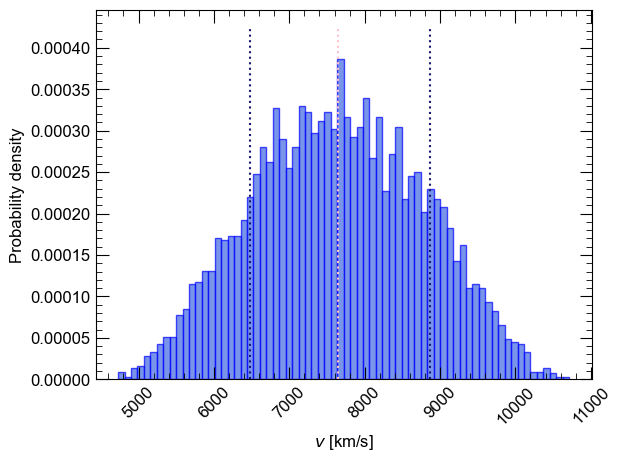

In [49]:
median = np.nanpercentile(v1_ccm,50)
low_lim = np.nanpercentile(v1_ccm,perc_low)
high_lim = np.nanpercentile(v1_ccm,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(v1_ccm,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

Median = 7363.837219110319 ; Lower limit =  6144.197961168584 ; Upper limit =  8625.988964757713


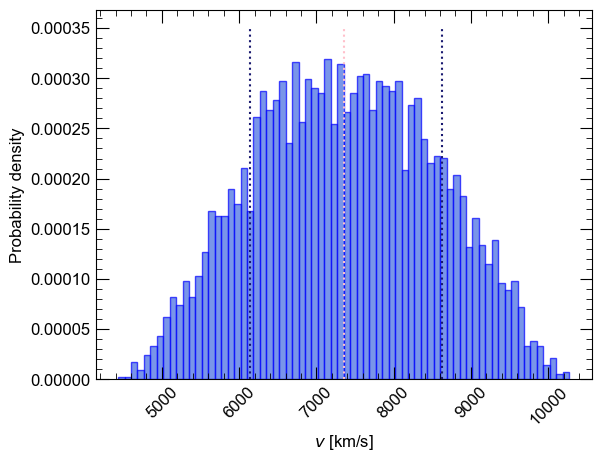

In [50]:
median = np.nanpercentile(v2_ccm,50)
low_lim = np.nanpercentile(v2_ccm,perc_low)
high_lim = np.nanpercentile(v2_ccm,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(v2_ccm,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

Median = 20157.10590347743 ; Lower limit =  19241.533369103738 ; Upper limit =  21047.566385913375


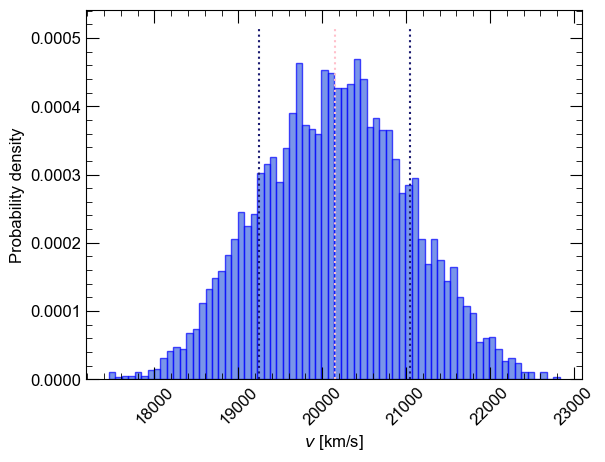

In [51]:
median = np.nanpercentile(v3_ccm,50)
low_lim = np.nanpercentile(v3_ccm,perc_low)
high_lim = np.nanpercentile(v3_ccm,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(v3_ccm,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

Median = 20056.478285634912 ; Lower limit =  19141.79374252589 ; Upper limit =  20941.873459940343


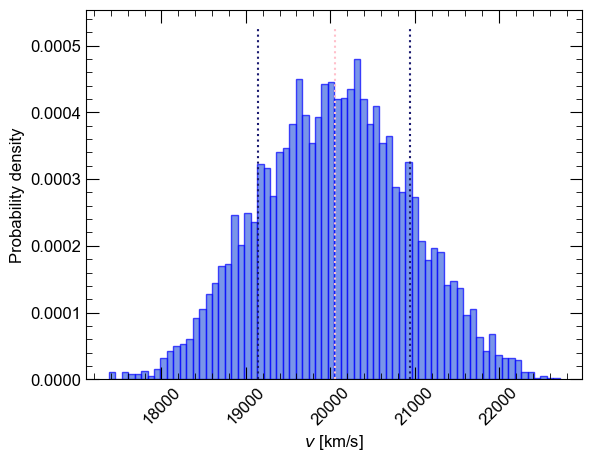

In [52]:
median = np.nanpercentile(v4_ccm,50)
low_lim = np.nanpercentile(v4_ccm,perc_low)
high_lim = np.nanpercentile(v4_ccm,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(v4_ccm,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

In [53]:
v1_ccm*1e5

array([7.91168555e+08, 8.40517075e+08, 8.36107403e+08, ...,
       8.16491163e+08, 6.44177348e+08, 7.24567127e+08])

In [54]:
median*1e5

2005647828.563491

Median = 1207.960481587105 ; Lower limit =  674.5291120014668 ; Upper limit =  1803.3475204587126


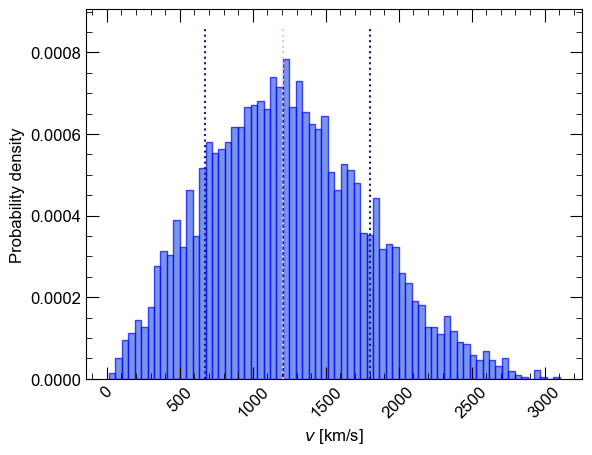

In [55]:
median = np.nanpercentile(vc_ccm,50)
low_lim = np.nanpercentile(vc_ccm,perc_low)
high_lim = np.nanpercentile(vc_ccm,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(vc_ccm,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

In [56]:
def diff(a,b):
    return a-b

Median = 6403.211718849565 ; Lower limit =  5105.132056269305 ; Upper limit =  7680.963569693182


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s
[Parallel(n_job

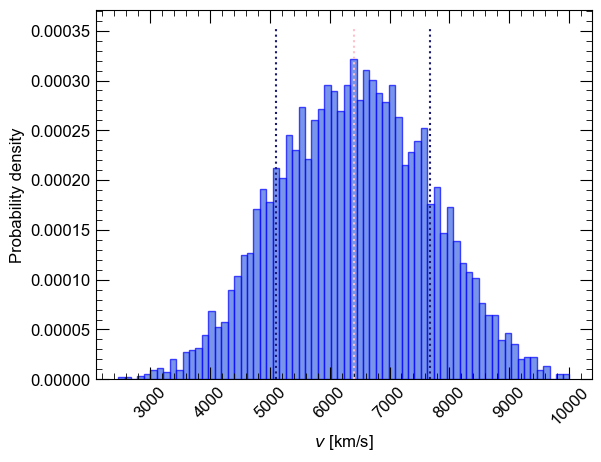

In [57]:
vdiff1 = Parallel(n_jobs=1, verbose=5)(delayed(diff)(v1_ccm[i],vc_ccm[i]) for i in range(niter))

median = np.nanpercentile(vdiff1,50)
low_lim = np.nanpercentile(vdiff1,perc_low)
high_lim = np.nanpercentile(vdiff1,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(vdiff1,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s
[Parallel(n_job

Median = 6125.310390999872 ; Lower limit =  4800.200258686969 ; Upper limit =  7478.022081343872


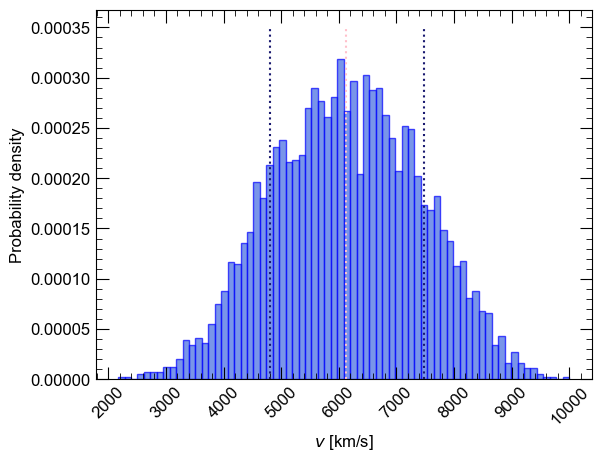

In [58]:
vdiff2 = Parallel(n_jobs=1, verbose=5)(delayed(diff)(v2_ccm[i],vc_ccm[i]) for i in range(niter))

median = np.nanpercentile(vdiff2,50)
low_lim = np.nanpercentile(vdiff2,perc_low)
high_lim = np.nanpercentile(vdiff2,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(vdiff2,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s
[Parallel(n_job

Median = 18923.501918904323 ; Lower limit =  17868.653603453382 ; Upper limit =  19962.231809064466


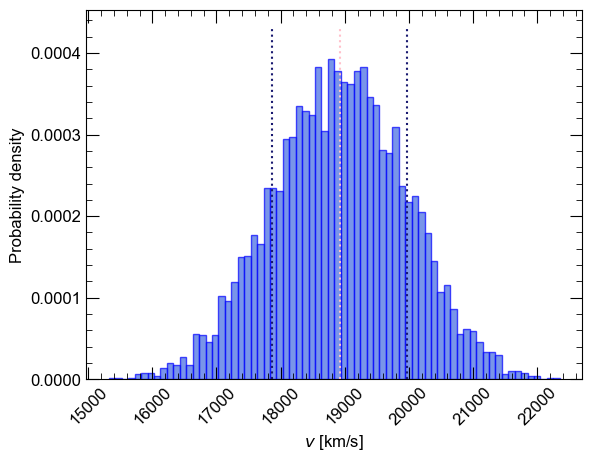

In [59]:
vdiff3 = Parallel(n_jobs=1, verbose=5)(delayed(diff)(v3_ccm[i],vc_ccm[i]) for i in range(niter))

median = np.nanpercentile(vdiff3,50)
low_lim = np.nanpercentile(vdiff3,perc_low)
high_lim = np.nanpercentile(vdiff3,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(vdiff3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 287 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 449 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 647 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 881 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1151 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1457 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 1799 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2177 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 2591 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3041 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 3527 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4049 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 4607 tasks      | elapsed:    0.0s
[Parallel(n_job

Median = 18825.69193349906 ; Lower limit =  17768.589011586937 ; Upper limit =  19861.40364274484


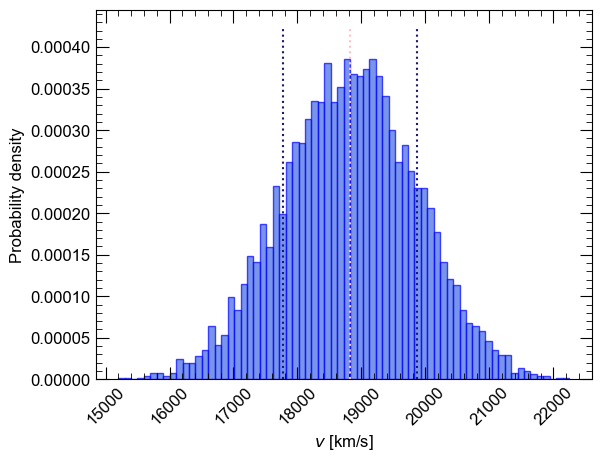

In [60]:
vdiff4 = Parallel(n_jobs=1, verbose=5)(delayed(diff)(v4_ccm[i],vc_ccm[i]) for i in range(niter))

median = np.nanpercentile(vdiff4,50)
low_lim = np.nanpercentile(vdiff4,perc_low)
high_lim = np.nanpercentile(vdiff4,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(vdiff4,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

### MC-based estimate of north lobe separation using the core position as a zero-point

In [106]:
def velocity_sep(year_array, sep_array, incl, dist10=0.85):
    vfit, vcov = curve_fit(linear, year_array, sep_array)
    vkms = (vfit[0]/np.sin(incl*np.pi/180))*(0.048*dist10*pc_km)/(365*24*3600)
    return vkms, vfit[0], vfit[1]

def velocity_sep2(year_array, sep_array):
    vfit, vcov = curve_fit(linear, year_array, sep_array)
    vkms = vfit[0]*pc_km/(365*24*3600)
    return vkms, vfit[0], vfit[1]

def mcmc(years, coords_core, coords, incl_array, niter=niter):
    sep_median = np.zeros(len(coords))
    sep_std = np.zeros(len(coords))
    sep = np.zeros((len(coords), niter))

    sep_median_pc = np.zeros(len(coords))
    sep_std_pc = np.zeros(len(coords))
    sep_pc = np.zeros((len(coords), niter))
    
    for i in range(len(coords)):
        coords_jet = coords[i]
        for j in range(niter):
            sep[i,j] = coords_core[j].separation(coords_jet[j]).arcsec
            sep_pc[i,j] = sep[i,j]/np.sin(incl_array[j]*np.pi/180)*(0.048*0.85)
        sep_median[i] = np.median(sep[i,:])
        sep_std[i] = np.std(sep[i,:])
        sep_median_pc[i] = np.median(sep_pc[i,:])
        sep_std_pc[i] = np.std(sep_pc[i,:])

    vel, m, q = np.zeros(niter), np.zeros(niter), np.zeros(niter)
    vel2, m2, q2 = np.zeros(niter), np.zeros(niter), np.zeros(niter)
    years = np.array(years)
    best_values, high_values, low_values = np.zeros(len(years)), np.zeros(len(years)), np.zeros(len(years))
    #for i in range(len(coords)):
    #print(year_array)
    #print(sep[:,0])
    for j in range(niter):
        #incl = incl_array[j]
        vel[j], m[j], q[j] = velocity_sep(np.array(years), sep[:,j], incl_array[j])
        vel2[j], m2[j], q2[j] = velocity_sep2(np.array(years), sep_pc[:,j])

    for i in range(len(years)):
        best_values[i] = np.median(m*years[i]+q)
        high_values[i] = np.percentile(m*years[i]+q, 84)
        low_values[i] = np.percentile(m*years[i]+q, 16)

    mask_vla = np.array([True, True, True, True, False])
    mask_mkt = ~mask_vla
        
    plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Helvetica"],
    })

    plt.style.use('dark_background')

    
    
    plt.figure(figsize=(12,10), dpi=600)
    #plt.gca().set_facecolor('indigo')
    #for j in range(niter):
        #plt.plot(years, linear(np.array(years), m[j], q[j]), alpha=0.01, color='lightgray')
    #plt.plot(years, linear(np.array(years), np.max(m), np.max(q)), alpha=0.1, color='hotpink')
    #plt.plot(years, linear(np.array(years), np.min(m), np.min(q)), alpha=0.1, color='hotpink')
    #plt.plot(years, np.median(linear(np.linspace(min(years),max(years)+1, np.size(m[j])), m[j], q[j])), color='k', ls='--')
    ##plt.errorbar(years, sep_median, sep_std, markersize=10, linestyle='', marker='o', color='darkmagenta')
    ##plt.plot(years, best_values, color='darkmagenta', linestyle='--')
    plt.errorbar(years[mask_vla], sep_median[mask_vla], sep_std[mask_vla], markersize=10, linestyle='', marker='o', color='aquamarine', label='VLA')
    plt.errorbar(years[mask_mkt], sep_median[mask_mkt], sep_std[mask_mkt], markersize=10, linestyle='', marker='o', color='hotpink', label='MeerKAT')
    plt.plot(years, best_values, color='mediumpurple', linestyle='--')
    #plt.plot(years, high_values, color='black', linestyle='dashdot')
    #plt.plot(years, low_values, color='black', linestyle='dashdot')
    plt.fill_between(years, low_values, high_values, color="mediumpurple", alpha=0.5, label="1$\sigma$ interval")
    plt.xlabel('Time [years]', fontsize=35)
    plt.ylabel('Separation from the core [arcsec]', fontsize=35)
    plt.gca().tick_params(labelsize=30)
    plt.legend(fontsize=30)
    legend = plt.gca().legend(fontsize=30)
    #legend.get_frame().set_facecolor('indigo')
    #legend.get_frame().set_edgecolor('white')
    #for text in legend.get_texts():
        #text.set_color('white')
    #plt.gca().tick_params(labelsize=19)
    #plt.gca().spines['bottom'].set_color('white')
    #plt.gca().spines['left'].set_color('white')
    #plt.gca().spines['top'].set_color('white')
    #plt.gca().spines['right'].set_color('white')
    #plt.gca().yaxis.label.set_color('white')
    #plt.gca().xaxis.label.set_color('white')
    #plt.grid()
    plt.savefig('RegionA_sep_black.pdf', bbox_inches='tight')
    plt.show()

    plt.figure()
    for j in range(niter):
        plt.plot(years, linear(np.array(years), m2[j], q2[j]), alpha=0.01, color='hotpink')
    plt.errorbar(years, sep_median_pc, sep_std_pc, capsize=3, linestyle='', marker='.')
    plt.xlabel('years')
    plt.ylabel('separation from the core [pc]')
    plt.grid()
    #plt.show()

    plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Arial"],
    })

    

    return sep_median, sep_std, vel, m, q

<>:73: SyntaxWarning: invalid escape sequence '\s'
<>:73: SyntaxWarning: invalid escape sequence '\s'
/var/folders/cc/fn259m2559x022m4vgvz10s00000gn/T/ipykernel_11620/620469900.py:73: SyntaxWarning: invalid escape sequence '\s'
  plt.fill_between(years, low_values, high_values, color="mediumpurple", alpha=0.5, label="1$\sigma$ interval")


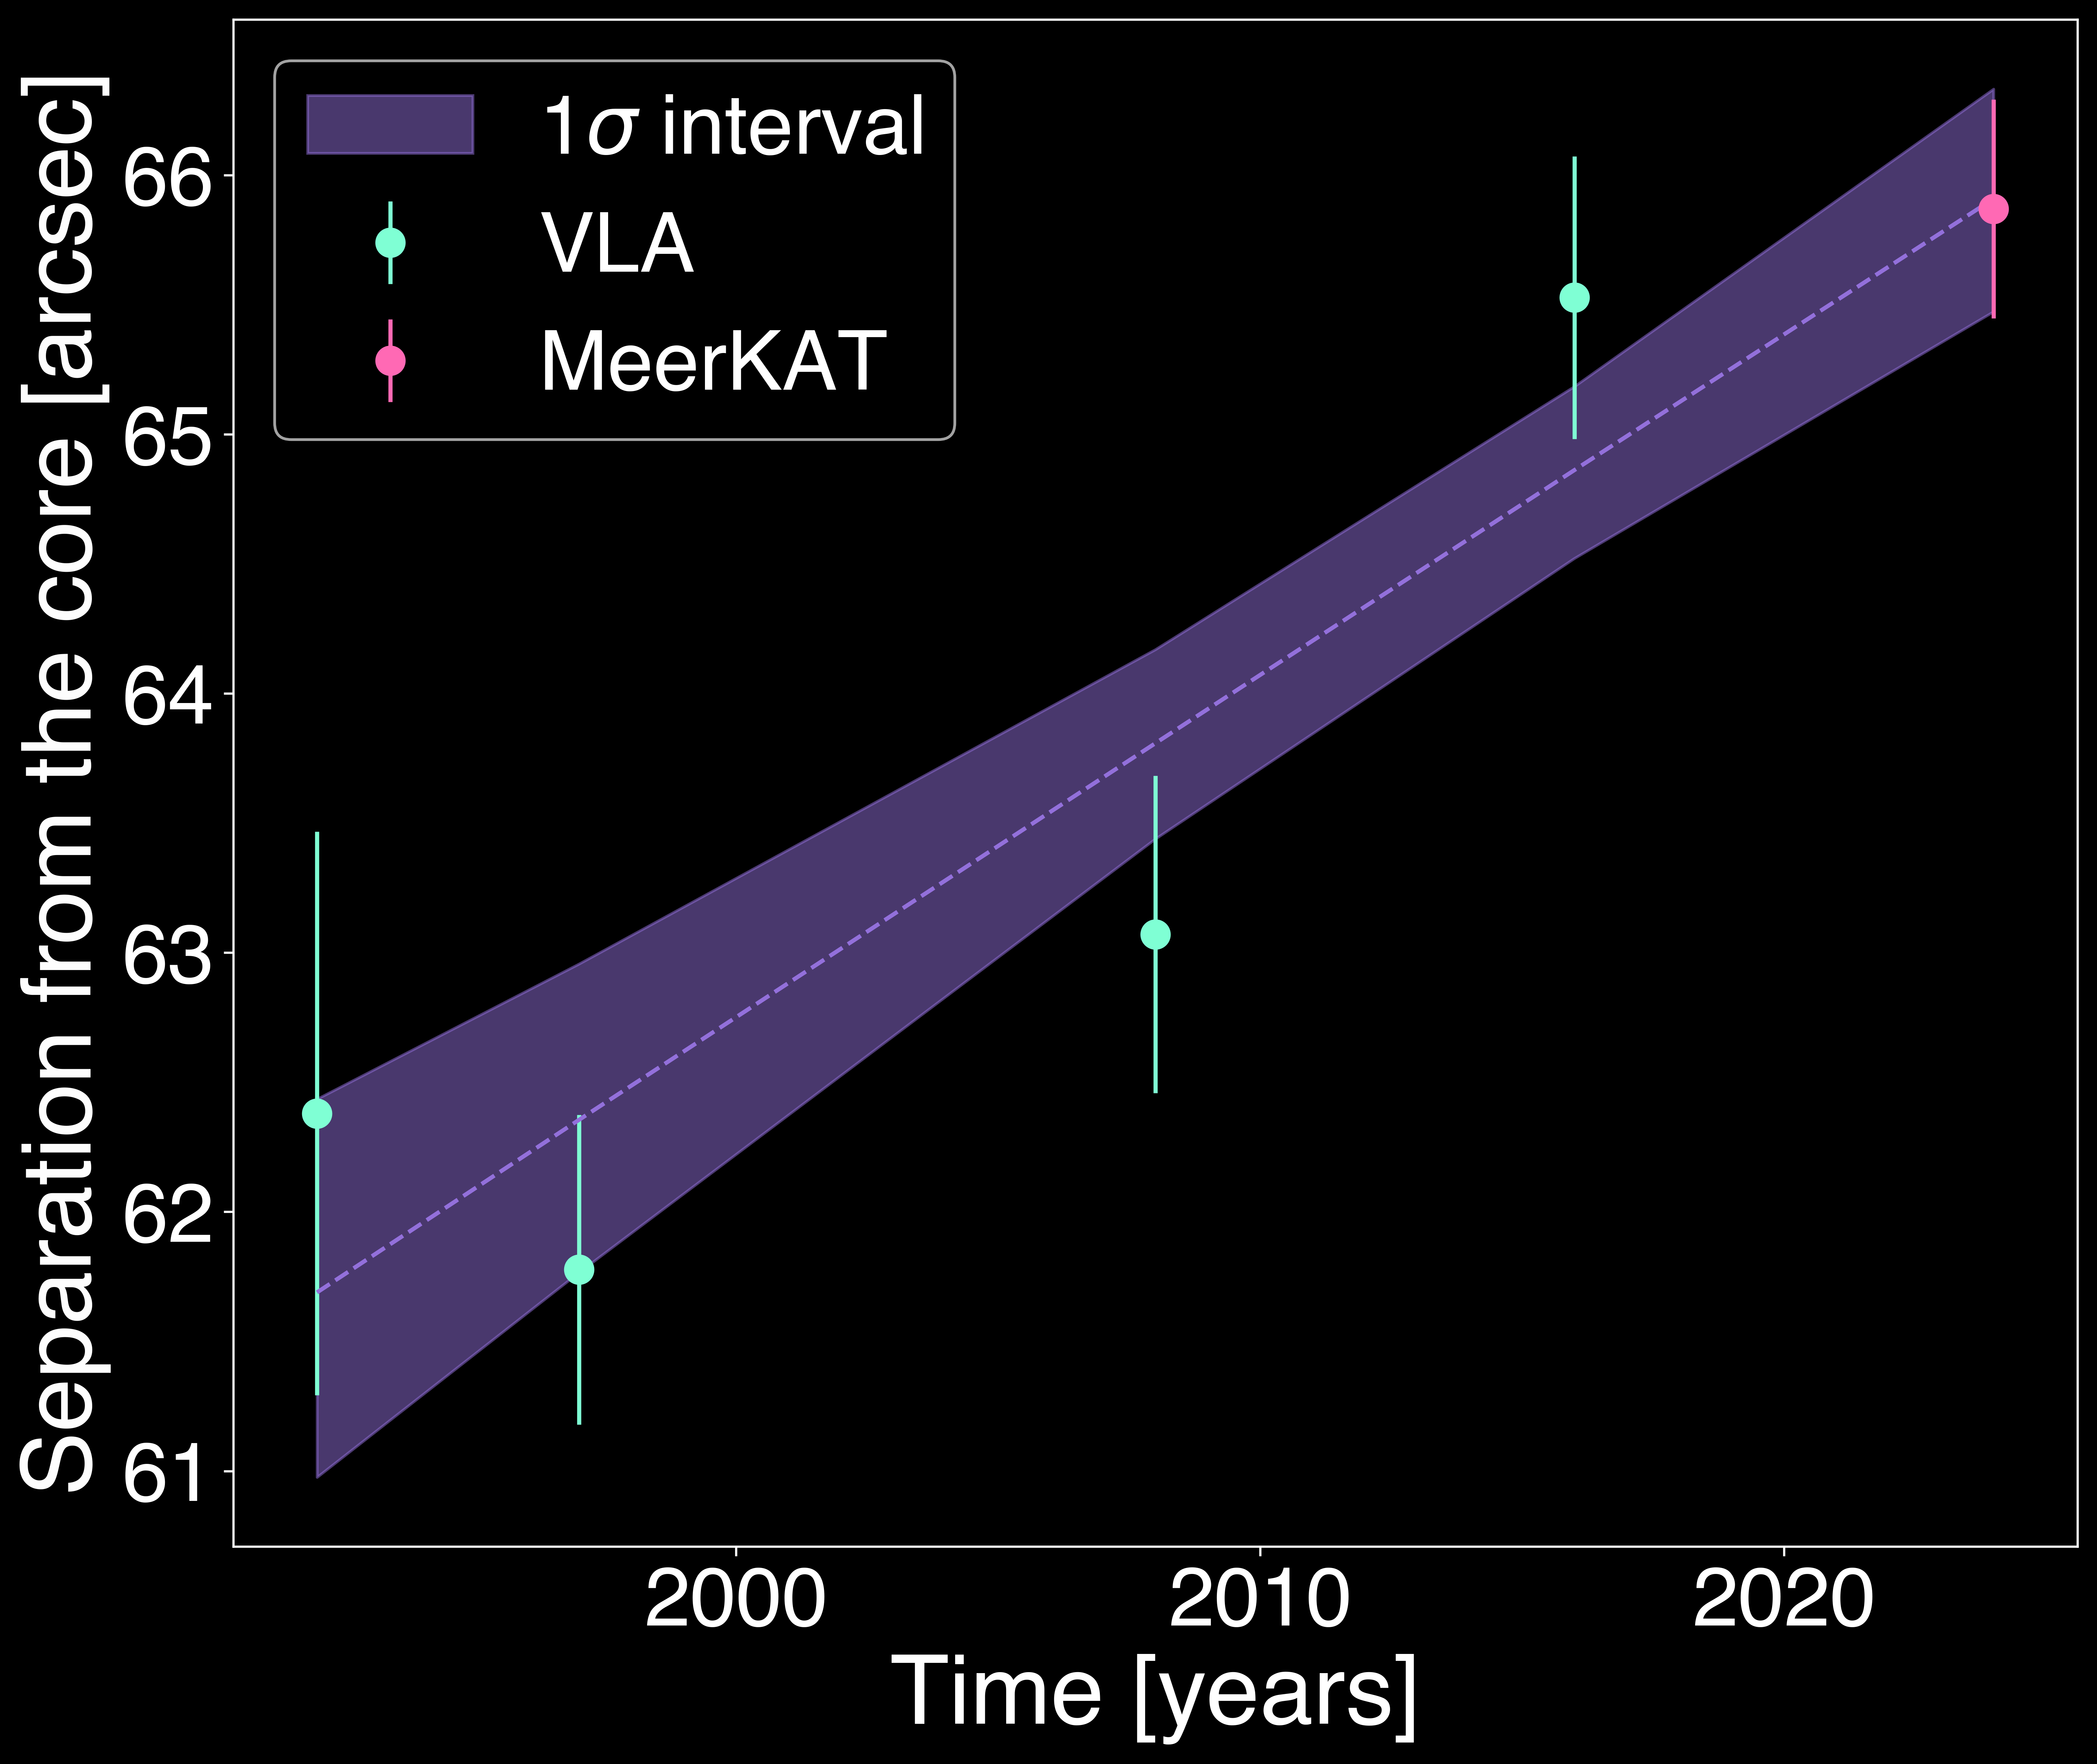

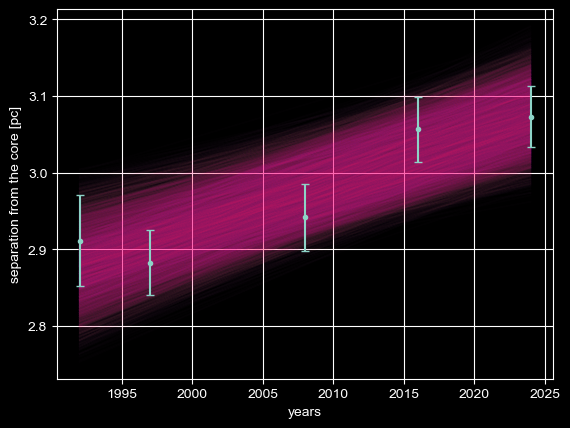

In [107]:
sep_median, sep_std, vel, m, q = mcmc([1992, 1997, 2008, 2016, 2024], coord_core_rand, [coord92_rand, coord97_rand, coord08_rand, coord16_rand, coord24_rand], incl_rand)

In [63]:
coord_core_rand[0].separation(coord97_rand[0]).arcsec

62.23862811781667

In [97]:
plt.style.use('default')

In [64]:
sep_median

array([62.37970658, 61.77681869, 63.07046467, 65.52762431, 65.86978215])

In [65]:
sep_std

array([1.08681542, 0.59763507, 0.61187389, 0.54531603, 0.42224735])

In [66]:
#np.std(sep)

In [67]:
vel

array([4972.51956911, 6569.28730389, 7842.78827432, ..., 5464.81761037,
       8954.93274382, 6918.89593838])

In [68]:
np.percentile(vel, 16)

4640.19115845877

In [69]:
np.percentile(vel, 86)

7448.083601861457

Median = 6007.933680895134 ; Lower limit =  4640.19115845877 ; Upper limit =  7366.324080029243


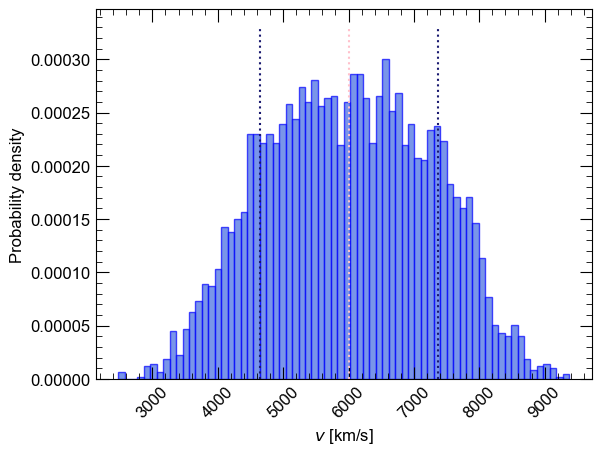

In [70]:
median = np.nanpercentile(vel,50)
low_lim = np.nanpercentile(vel,perc_low)
high_lim = np.nanpercentile(vel,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(vel,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

Median = 131.45478723515814 ; Lower limit =  101.63016383300065 ; Upper limit =  161.43381221500482


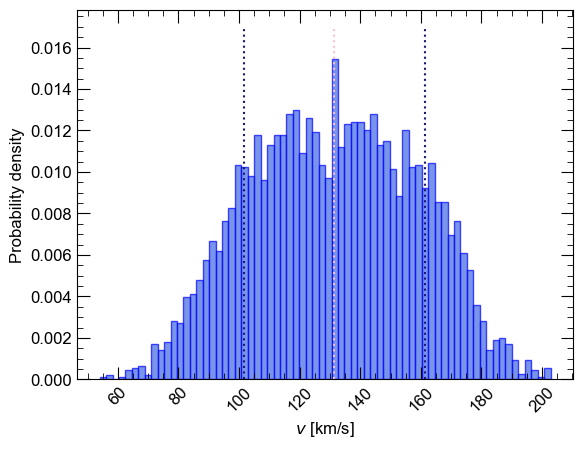

In [71]:
median = np.nanpercentile(m*1e3,50)
low_lim = np.nanpercentile(m*1e3,perc_low)
high_lim = np.nanpercentile(m*1e3,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(m*1e3,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'$v$ [km/s]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

In [72]:
with open('vel.pkl', 'wb') as f:
    pickle.dump(vel, f)

Median = 1523.0859762909602 ; Lower limit =  1378.6028725639776 ; Upper limit =  1613.5373461494921


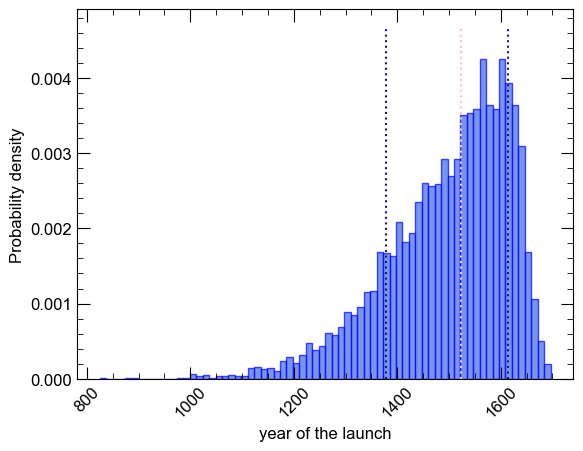

In [73]:
median = np.nanpercentile(-q/m,50)
low_lim = np.nanpercentile(-q/m,perc_low)
high_lim = np.nanpercentile(-q/m,perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(-q/m,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'year of the launch', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

Median = 500.91402370903984 ; Lower limit =  410.46265385050793 ; Upper limit =  645.3971274360225


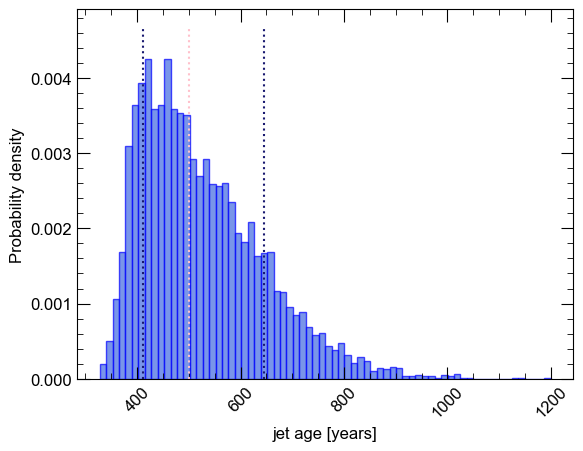

In [74]:
median = np.nanpercentile(2024-(-q/m),50)
low_lim = np.nanpercentile(2024-(-q/m),perc_low)
high_lim = np.nanpercentile(2024-(-q/m),perc_up)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(2024-(-q/m),bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'jet age [years]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

In [75]:
2024+low_lim

2434.462653850508

Median = 2192.280089802709 ; Lower limit =  2132.111939940207 ; Upper limit =  2256.3242301998566


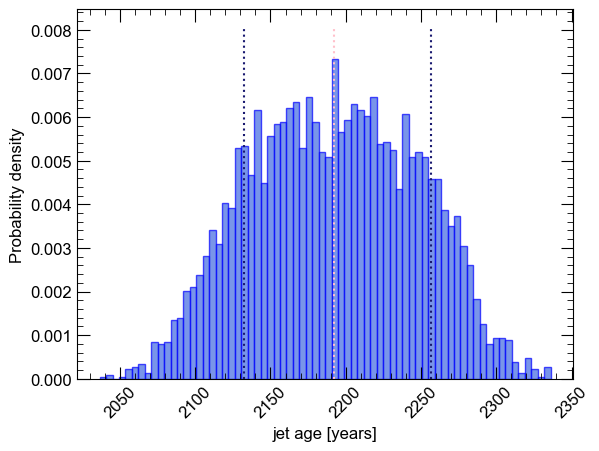

In [76]:
median = np.nanpercentile(abs(q)+1992,50)
low_lim = np.nanpercentile(abs(q)+1992,16)
high_lim = np.nanpercentile(abs(q)+1992,86)

print('Median =',median,'; Lower limit = ',low_lim,'; Upper limit = ',high_lim)

histplot = plt.hist(abs(q)+1992,bins=70,color='royalblue',edgecolor='blue',density=True,alpha=0.7)
plt.vlines([low_lim,high_lim],0,max(histplot[0])*1.1,linestyles=':',colors='midnightblue')
plt.vlines(median,0,max(histplot[0])*1.1,linestyles=':',colors='pink')
#plt.ylim(0,max(histplot[0])*1.1)
plt.ylabel('Probability density', fontsize=12)
plt.xlabel(r'jet age [years]', fontsize=12)
#plt.xlim(-1e5,1e5)
#plt.title(str(name))
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tick_params(axis='both', which='major', length=9)
plt.tick_params(axis='both', which='minor', length=4.5)
plt.tick_params(axis='both', which='both',direction='in',right=True,top=True)
plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
plt.xticks(rotation=45)
#plt.savefig(str(name)+'_peculiar_velocity.png')
plt.show()
plt.close()

In [77]:
print(np.sqrt(1/(1-(np.median(vel)/c)**2)))

1.0002005895998882


In [78]:
print(np.median(vel/c))

0.02002644560298378
